# 📚 Introduction

Kidney stone disease is one of the most common urological disorders, and accurate detection using imaging techniques plays a vital role in early diagnosis and treatment. Recent advances in **Deep Learning** and **Convolutional Neural Networks (CNNs)** have opened new opportunities for improving classification performance in medical imaging tasks. However, applying these methods to real-world datasets presents several challenges, such as **imbalanced data distribution, variations in image quality, limited dataset size, and computational restrictions**.

In this project, we aimed to develop and evaluate multiple deep learning models to classify kidney stone images. Our goal was not only to compare the performance of different architectures but also to build a **robust pipeline** that ensures:

* ✅ **Efficient preprocessing and augmentation** to handle dataset imbalance and image diversity.
* ✅ **Fair and consistent training strategies** using `tf.data.Dataset`, GPU acceleration (T4×2), and `MirroredStrategy`.
* ✅ **Reliable evaluation** with metrics beyond accuracy, including **Recall, Precision, and F1-score**, which are especially important in the medical domain where false negatives can have critical consequences.
* ✅ **Systematic experimentation** with both **classical CNNs (AlexNet, VGGNet, ResNet34)** and **modern architectures (EfficientNet B0, B1, B2)** to analyze strengths and weaknesses.
* ✅ **Modular pipeline** that saves predictions for each model in separate CSV files, ensuring reproducibility and easy comparison across experiments.

This approach allowed us to investigate **how simpler models compare against more complex ones in a challenging real-world dataset**, and whether advanced architectures always outperform classical networks.



## **📖 Project Overview**

Kidney stone detection from medical imaging is a **challenging task** due to factors such as noise in data, limited dataset size, and high inter-class similarity.
In this project, we aimed to **develop, train, and evaluate multiple deep learning models** to identify kidney stones with a robust and reproducible pipeline.

## **📖 Our Modeling Strategy**

To ensure fairness and reliability in comparison:

* **Multiple architectures** were used: `AlexNet`, `VGGNet`, `ResNet34`, `EfficientNets` B0, B1, B2.
* Training was performed with:

  * Input size: **96×96**
  * Batch size: **32**
  * Dropout: **0.5**
  * Learning rate: **0.001**
  * Data size: **200,000 samples**
* Training was split into two phases (**10 + 10 epochs**) to overcome Kaggle’s time limitation (12 hours/session).
* GPU setup: **T4x2 with MirroredStrategy** for efficient training.

## **📖 Challenges & Solutions**

* **Challenge 1:** Training time limits on Kaggle.
  **Solution:** Split training into two sessions with checkpoint saving.

* **Challenge 2:** Class imbalance and unstable metrics.
  **Solution:** Adopted evaluation metrics beyond accuracy (**Recall, Precision, F1-score**) and monitored validation trends.

* **Challenge 3:** Overfitting in complex models.
  **Solution:** Applied **Dropout, Batch Normalization, EarlyStopping, and ReduceLROnPlateau** to stabilize training.

## **📖 Evaluation Metrics**

To provide a fair comparison and highlight the **clinical relevance**, the following metrics were used:

* **Accuracy**
* **Precision**
* **Recall (Sensitivity)** → critical in medical tasks
* **F1-score**
* **Confusion Matrix & Classification Report**



# 📁 1. Import Libraries & Config

In [1]:
# Import Libraries

import os
import numpy as np
import pandas as pd
import cv2
import random
import re

from glob import glob
import time
import json
import gc

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc, log_loss

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0, EfficientNetB1, EfficientNetB2

# for "Clear TensorFlow/Keras session before building a new model"
from tensorflow.keras import mixed_precision
from tensorflow.keras import backend as K 

2025-08-27 16:25:09.521086: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756311909.723166      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756311909.781556      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## - Test GPUs

In [2]:
# GPU error prevention and detection of GPU usage

# - Enable memory growth
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# - GPU or CPU is using
gpu_devices = tf.config.list_physical_devices('GPU')
if len(gpu_devices) > 1:
    print('✅ Two GPUs are using') 
elif len(gpu_devices) == 1:
    print('✅ GPU is using') 
else: 
    print('⚠️ CPU is using')


✅ Two GPUs are using


# 💽 2. Load Dataset

In [3]:
# 2. Load Dataset
    # - From: "/kaggle/input/kidney-stone-classification-and-object-detection"

data_dir = "/kaggle/input/kidney-stone-classification-and-object-detection"
class_names = os.listdir(data_dir)
print("Classes:", class_names)

for class_name in class_names:
    folder_path = os.path.join(data_dir, class_name)
    print(f"{class_name}: {len(os.listdir(folder_path))} images")

Classes: ['stone', 'Normal']
stone: 5002 images
Normal: 4414 images


In [4]:
# Upload photos separately "normal" and "stone"

image_list_stone = sorted(glob(data_dir + "/stone/*.JPG"))
image_list_normal = sorted(glob(data_dir + "/Normal/*.JPG"))


In [5]:
len(image_list_stone)

5002

In [6]:
len(image_list_normal)

4414

In [7]:
# Create DataFrames
df_normal = pd.DataFrame({'image_path': image_list_normal, 'label': 0})
df_stone = pd.DataFrame({'image_path': image_list_stone, 'label': 1})

df_all = pd.concat([df_normal, df_stone], ignore_index=True)
df_all = df_all.sample(frac=1, random_state=42).reset_index(drop=True)

df = df_all
df.head()

,image_path,label
0,/kaggle/input/kidney-stone-classification-and-...,1
1,/kaggle/input/kidney-stone-classification-and-...,0
2,/kaggle/input/kidney-stone-classification-and-...,1
3,/kaggle/input/kidney-stone-classification-and-...,0
4,/kaggle/input/kidney-stone-classification-and-...,1


# 📊 3.Exploratory Data Analysis (EDA)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9416 entries, 0 to 9415
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  9416 non-null   object
 1   label       9416 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 147.3+ KB
None


In [9]:
print(df.isnull().sum())

image_path    0
label         0
dtype: int64


In [10]:
print(df.duplicated().sum())

0


## - Sample Images and Class Distribution

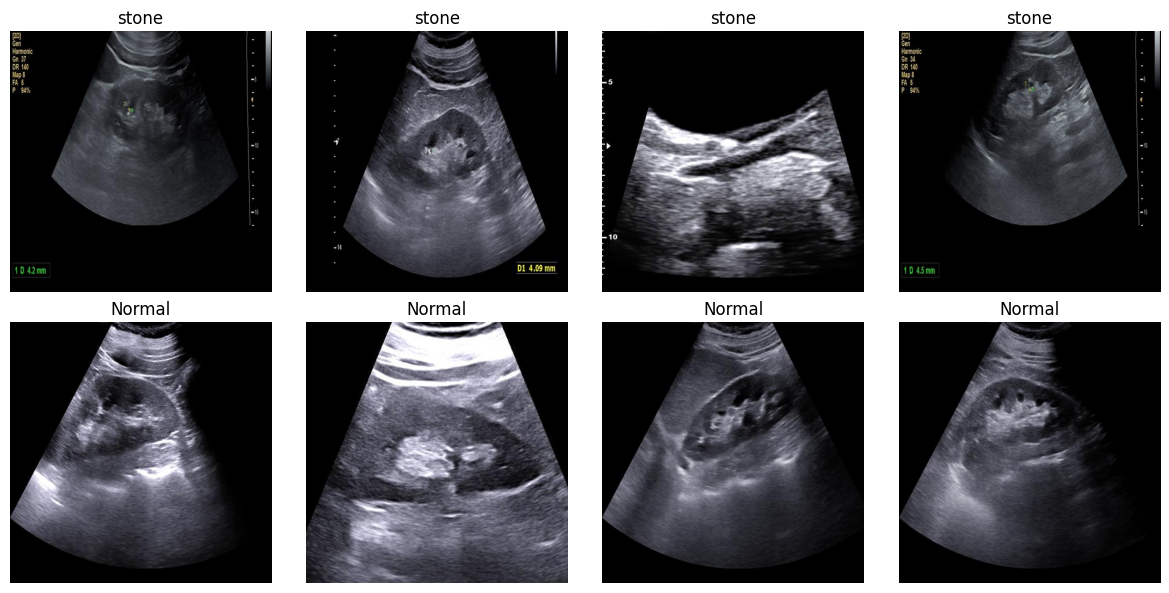

In [11]:
# Show some sample images from each class

def show_sample_images(data_dir, class_names, img_per_class=4):
    plt.figure(figsize=(12, 6))
    for i, class_name in enumerate(class_names):
        img_list = os.listdir(os.path.join(data_dir, class_name))
        for j in range(img_per_class):
            img_path = os.path.join(data_dir, class_name, img_list[j])
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(len(class_names), img_per_class, i * img_per_class + j + 1)
            plt.imshow(img)
            plt.axis('off')
            plt.title(class_name)
    plt.tight_layout()
    plt.show()

show_sample_images(data_dir, class_names)


### Convert Numerical Labels to String

In [12]:
# Convert numerical labels to string format for ImageDataGenerator
df_all['label'] = df_all['label'].map({0: 'Normal', 1: 'Stone'})

### Show Some Image and Calculate the Ratio of Images

Label: Normal


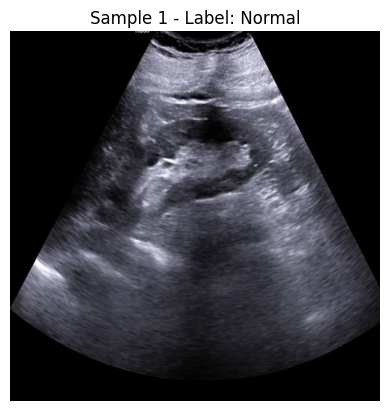

Label: Stone


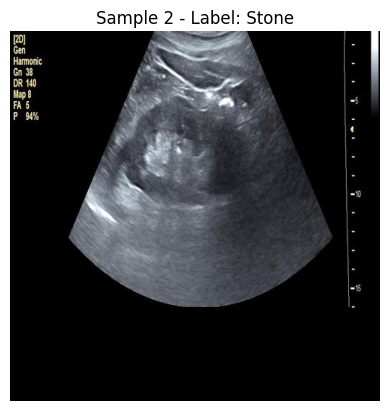

Label: Stone


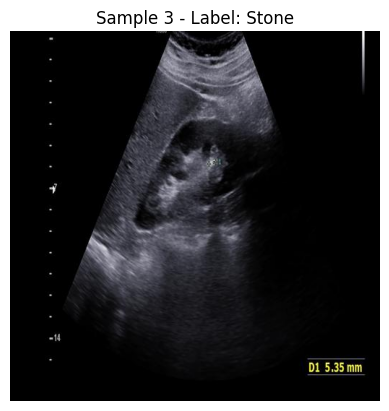

Label: Stone


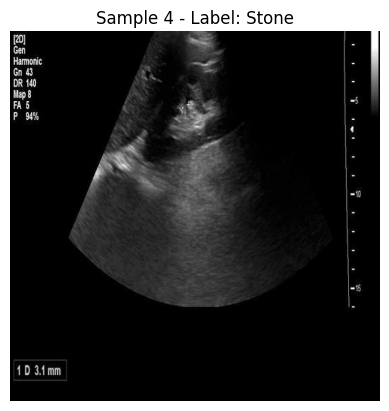

Label: Stone


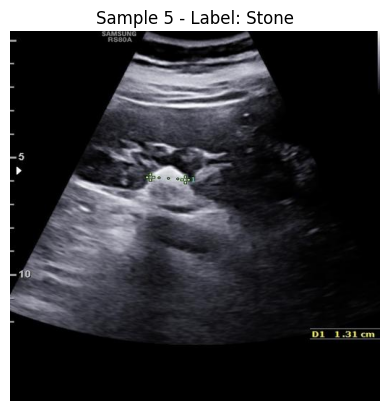

🔍 Dimensions of the last image:
The height is: 512
The width is: 512


In [13]:
# Display 5 random images from the dataframe
for i in range(5):
    rand_idx = random.randint(0, len(df) - 1)
    img_path = df.iloc[rand_idx]['image_path']  
    label = df.iloc[rand_idx]['label']
    
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    print(f"Label: {label}")
    plt.imshow(img_rgb)
    plt.title(f"Sample {i+1} - Label: {label}")
    plt.axis('off')
    plt.show()

    # We keep the last image for dimension checking.
    if i == 4:
        last_img = img

# Check the dimensions of the last image
height, width = last_img.shape[:2]
print("🔍 Dimensions of the last image:")
print("The height is:", height)
print("The width is:", width)


## Class Distribution

In [14]:
df['label'].value_counts(normalize=True)

label
Stone     0.531223
Normal    0.468777
Name: proportion, dtype: float64

### Display a bar chart

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


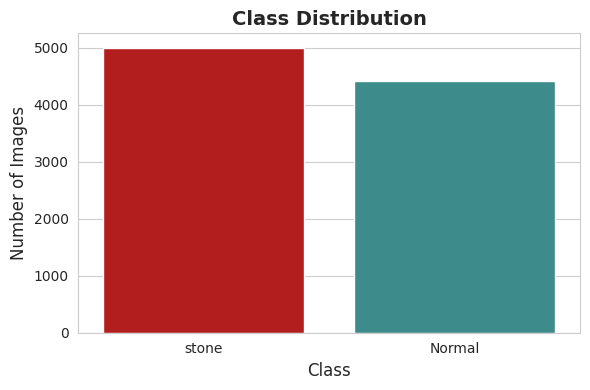

In [15]:
sns.set_style('whitegrid')  # or "darkgrid"

colors = ['#CB0404', '#309898']  

counts = {cls: len(os.listdir(os.path.join(data_dir, cls))) for cls in class_names}

# Drawing a bar chart
plt.figure(figsize=(6, 4))
sns.barplot(
    x=list(counts.keys()),
    y=list(counts.values()),
    palette=colors
)

plt.title("Class Distribution", fontsize=14, weight='bold')
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


# 🧹 4. Data Preprocessing

### 🔍 Why We Use `ImageDataGenerator.flow_from_dataframe()` Instead of `tf.data.Dataset.from_generator()`

In this project, we intentionally choose `ImageDataGenerator.flow_from_dataframe()` over `tf.data.Dataset.from_generator()` for several practical and performance-related reasons:

- ✅ **Built-in support for image loading and augmentation**: `ImageDataGenerator` offers seamless integration with Keras' preprocessing pipeline, enabling on-the-fly image resizing, normalization, and augmentation with minimal code.
- ✅ **Better integration with image paths**: Our dataset consists of file paths and labels stored in a pandas DataFrame. `flow_from_dataframe()` is designed specifically to handle this structure natively, without needing a custom generator function.
- ✅ **Optimized batch control**: It handles batching, shuffling, and labeling internally, and supports ensuring complete batches (`drop_remainder`) automatically.
- ✅ **Reduced complexity and improved readability**: Compared to defining a Python generator and wrapping it with `tf.data.Dataset.from_generator`, this approach is cleaner, more concise, and easier to debug.
- ✅ **TensorFlow strategy-aware**: Works seamlessly with distributed training strategies like `tf.distribute.MirroredStrategy`.

> **In summary**, based on my previous experiences, this approach simplifies the **data pipeline**, increases efficiency, and enhances maintainability for image classification tasks.

#imageclassification #tensorflow #flowfromdataframe #ImageDataGenerator #deeplearning #medicalAI #keras #mirroredstrategy #datapipeline


## I. Define Hyperparameters

> **Note:**
> - I considered height and width to be in a **96*96 format**, but since overfitting affects it, you can *change it to 128*128*. I will test the optimal batch size by setting *BatchSize values to 8, 16, and 32,* and ultimately set the **Batch size to 32**.

In [16]:
BATCH_SIZE = 32

IMG_HEIGHT, IMG_WIDTH = 96, 96

INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3) # RGB image input (input 3D)

SEED = 42

EPOCHS = 15 # Changed from "EPOCHS = 10"

NUM_CLASSES = 2

### - Create initial DataFrames with string labels

In [17]:
# Create initial DataFrames with string labels
df_normal = pd.DataFrame({'image_path': image_list_normal, 'label': 'Normal'})
df_stone  = pd.DataFrame({'image_path': image_list_stone,  'label': 'Stone'})

In [18]:
df_normal.head()

,image_path,label
0,/kaggle/input/kidney-stone-classification-and-...,Normal
1,/kaggle/input/kidney-stone-classification-and-...,Normal
2,/kaggle/input/kidney-stone-classification-and-...,Normal
3,/kaggle/input/kidney-stone-classification-and-...,Normal
4,/kaggle/input/kidney-stone-classification-and-...,Normal


In [19]:
df_stone.head()

,image_path,label
0,/kaggle/input/kidney-stone-classification-and-...,Stone
1,/kaggle/input/kidney-stone-classification-and-...,Stone
2,/kaggle/input/kidney-stone-classification-and-...,Stone
3,/kaggle/input/kidney-stone-classification-and-...,Stone
4,/kaggle/input/kidney-stone-classification-and-...,Stone


## II. Split Data to Train/Valid/Test

### 🧪 Data Splitting and Generator Creation with Batch Alignment for Multi-GPU Training

To ensure balanced training and consistent evaluation, we split the dataset **separately for each class (Normal & Stone)** before merging them back. This guarantees each split has a proportional number of samples per class (stratification).  
We also ensure that the number of samples in each dataset (`train/val/test`) is perfectly divisible by the batch size. This avoids **incomplete batches**, especially important when using `tf.distribute.MirroredStrategy` for multi-GPU training.  

> **This preparation** ensures robust, **scalable**, and **GPU-compatible** data feeding throughout training and evaluation.

#deeplearning #tensorflow #medicalAI #balanceddata #flowfromdataframe #categorical #gpuoptimization #mirroredstrategy


> **Note:**
> 
> **📌 The number of samples: divisible by "batch_size * num_GPUs"**
> 
> The total number of samples in each training, evaluation, and testing subset **must be divisible by (batch_size * num_GPUs)**, not just `batch_size`. This is because TensorFlow divides the data across GPUs when using `MirroredStrategy`.
>
> ✅ For example, in our case:
>
> **GPU = 2** and
**BATCH_SIZE = 32**.
*All data divisions must be **divisible by 64**.*

### Create Dataframes for Train, Validation and Test

In [20]:
# Split each class separately

train_ratio, val_ratio, test_ratio = 0.7, 0.2, 0.1

NUM_GPUS = len(tf.config.list_physical_devices('GPU'))
if NUM_GPUS == 0: NUM_GPUS += 1
EFFECTIVE_BATCH = BATCH_SIZE * NUM_GPUS

def classwise_split(image_list, label):
    total = len(image_list)
    train_count = int((train_ratio * total) // EFFECTIVE_BATCH * EFFECTIVE_BATCH)
    val_count   = int((val_ratio * total)  // EFFECTIVE_BATCH * EFFECTIVE_BATCH)
    test_count  = int((test_ratio * total) // EFFECTIVE_BATCH * EFFECTIVE_BATCH)

    total_count = train_count + val_count + test_count
    image_list = random.sample(image_list, total_count)

    train = image_list[:train_count]
    val   = image_list[train_count:train_count + val_count]
    test  = image_list[train_count + val_count:]

    df_train = pd.DataFrame({'image_path': train, 'label': label})
    df_val   = pd.DataFrame({'image_path': val,   'label': label})
    df_test  = pd.DataFrame({'image_path': test,  'label': label})

    return df_train, df_val, df_test


In [21]:
df_train_normal, df_val_normal, df_test_normal = classwise_split(image_list_normal, 'Normal')
df_train_stone,  df_val_stone,  df_test_stone  = classwise_split(image_list_stone,  'Stone')

### Combine Datasets

In [22]:
# Combine, Shuffle and Report
df_train = pd.concat([df_train_normal, df_train_stone]).sample(frac=1, random_state=SEED).reset_index(drop=True)
df_val   = pd.concat([df_val_normal, df_val_stone]).sample(frac=1, random_state=SEED).reset_index(drop=True)
df_test  = pd.concat([df_test_normal, df_test_stone]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Total training samples: {len(df_train)}")
print(f"Total validation samples: {len(df_val)}")
print(f"Total testing samples: {len(df_test)}")

Total training samples: 6528
Total validation samples: 1792
Total testing samples: 832


In [23]:
df_train.head(10)

,image_path,label
0,/kaggle/input/kidney-stone-classification-and-...,Stone
1,/kaggle/input/kidney-stone-classification-and-...,Stone
2,/kaggle/input/kidney-stone-classification-and-...,Normal
3,/kaggle/input/kidney-stone-classification-and-...,Stone
4,/kaggle/input/kidney-stone-classification-and-...,Normal
5,/kaggle/input/kidney-stone-classification-and-...,Stone
6,/kaggle/input/kidney-stone-classification-and-...,Stone
7,/kaggle/input/kidney-stone-classification-and-...,Stone
8,/kaggle/input/kidney-stone-classification-and-...,Normal
9,/kaggle/input/kidney-stone-classification-and-...,Normal


In [24]:
df_test.head(10)

,image_path,label
0,/kaggle/input/kidney-stone-classification-and-...,Stone
1,/kaggle/input/kidney-stone-classification-and-...,Stone
2,/kaggle/input/kidney-stone-classification-and-...,Normal
3,/kaggle/input/kidney-stone-classification-and-...,Stone
4,/kaggle/input/kidney-stone-classification-and-...,Normal
5,/kaggle/input/kidney-stone-classification-and-...,Stone
6,/kaggle/input/kidney-stone-classification-and-...,Stone
7,/kaggle/input/kidney-stone-classification-and-...,Normal
8,/kaggle/input/kidney-stone-classification-and-...,Normal
9,/kaggle/input/kidney-stone-classification-and-...,Stone


## III. Data Augmentation and Rescale

In [25]:
# Data Augmentation Setup
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

## IV. Input Model

We convert labels to **categorical** (instead of binary) for compatibility with `Softmax`-based output layers and accurate loss calculations via `categorical_crossentropy`.

## 📌 Final Data Pipeline Strategy (Multi-GPU Compatible)

After several iterations, we discovered the most stable setup for TensorFlow's multi-GPU training:

### 🔍 Data Pipeline Optimization – Final Resolution

After extensive testing, errors, and deep investigation into TensorFlow internals, we finalized the data pipeline for training and evaluation using `ImageDataGenerator` and `tf.data.Dataset`. The core question was:

> ❓ Should we **remove `batch_size` from `flow_from_dataframe`** and apply batching **only in `tf.data.Dataset.from_generator()`**?

#### 🔎 Final Conclusion: ❌ NO

`ImageDataGenerator.flow_from_dataframe()` always returns **batched** data. Even if you omit the `batch_size` argument, TensorFlow will **default to 32**. This means the data returned already has a shape of `(batch_size, H, W, C)`.

As a result, applying `.batch()` again in `tf.data.Dataset` leads to **nested batching**, which results in incorrect shapes like `(None, None, H, W, C)` — incompatible with model training.

---

#### ✅ Final Recommendation Table

| Scenario | Valid? | Explanation |
|----------|--------|-------------|
| Remove `batch_size` from `flow_from_dataframe` and batch later in `tf.data.Dataset` | ❌ Not Valid | `flow_from_dataframe` returns batched data by default. |
| Use batching only in `tf.data.Dataset.from_generator()` | ❌ Not Possible | Generator output is already batched. Re-batching results in invalid nested shapes. |
| Use `batch_size` in `flow_from_dataframe` and skip `.batch()` later | ✅ Recommended | Ensures correct shape and avoids double batching. Works best with `strategy.scope()` and multi-GPU training. |

---

### 💡 Implementation Tips:

- Always define `batch_size` inside `flow_from_dataframe(...)`.
- When wrapping the generator in `tf.data.Dataset.from_generator`, **do not use `.batch()`** again.
- Validate that `len(trainDataset) % strategy.num_replicas_in_sync == 0` to avoid training interruptions on multiple GPUs.

This pipeline ensures full compatibility with `tf.distribute.MirroredStrategy`, avoids shape mismatches, and leverages efficient data prefetching via `tf.data`.



> **Note:**
>
> ✅ After thorough research and various errors and corrections that we have made, **this is the best method for multi-GPU training without inconsistencies or re-batching!**



### - Data Distribution Across GPUs

In [26]:
# Load Data Using flow_from_dataframe

trainDataset = train_datagen.flow_from_dataframe(
    dataframe=df_train,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,  # ❌ batch_size=1 for trainDataset
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

valDataset = val_test_datagen.flow_from_dataframe(
    dataframe=df_val,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

testDataset = val_test_datagen.flow_from_dataframe(
    dataframe=df_test,
    x_col="image_path",
    y_col=None,  # <--- No label column
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode=None,  # <--- No class mode
    shuffle=False  # <--- So prediction order aligns with dataframe
)


Found 6528 validated image filenames belonging to 2 classes.
Found 1792 validated image filenames belonging to 2 classes.
Found 832 validated image filenames.


> **📌Note:**
>
> We created two test datasets: an **unlabeled dataset** called `testDataset` for predictions, and a **labeled dataset** named `testDataset_with_labels` for model evaluation. We generated labeled test data to assess the model's performance.

In [27]:
# Generate labeled test data to evaluate the model's performance
testDataset_with_labels = val_test_datagen.flow_from_dataframe(
    dataframe=df_test,
    x_col="image_path",
    y_col="label",  # label column  in testDataset
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",  # one-hot
    shuffle=False 
)

Found 832 validated image filenames belonging to 2 classes.


### 🔎 `tf.data.Dataset.from_generator` for **trainDataset**

To effectively distribute the data, **strategy.experimental_distribute_dataset()** was used. This allows a **more efficient distribution of data across GPUs**. Without this, the `loss` in modeling will face `NaN` values.

When using the GPU T4x2 in Kaggle with MirroredStrategy enabled to run the model on two GPUs, it is necessary to use `tf.data.Dataset.from_generator` for **trainDataset**, as flow_from_dataframe cannot be used directly with MirroredStrategy. However, this is not required for test data, where prediction and evaluation are performed.

### 📚 Reference sources: 

- Using `batch(BATCH_SIZE * num_replicas)` as per the official standard for global batch before **splitting to GPUs**

  [keras.io](https://keras.io/guides/distributed_training_with_tensorflow)

  [tensorflow.org](https://www.tensorflow.org/tutorials/distribute/custom_training)

  [tensorflow.org](https://www.tensorflow.org/tutorials/distribute/keras?utm_source=chatgpt.com)

  [cran.r-project.org](https://cran.r-project.org/web/packages/keras3/vignettes/distributed_training_with_tensorflow.html)


> **Note:**
>
> ⚠ Given our settings in this modeling **(Softmax output + categorical_crossentropy + two classes)**, this function is the most appropriate and cleanest example to use in **training**.
  

In [28]:
# A function that converts the Generator to a tf.data.Dataset [Usable for training]

def dataset_from_generator(generator, has_labels=True):
    import tensorflow as tf
    if has_labels:
        return tf.data.Dataset.from_generator(
            lambda: generator,
            output_signature=(
                tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32),
                tf.TensorSpec(shape=(BATCH_SIZE, NUM_CLASSES), dtype=tf.float32)
            )
        ).prefetch(tf.data.AUTOTUNE)  # ✅ no ".batch()"!
    else:
        return tf.data.Dataset.from_generator(
            lambda: generator,
            output_signature=tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32)
        ).prefetch(tf.data.AUTOTUNE)

In [29]:
'''
# A function that converts the Generator to a tf.data.Dataset [Usable for training, validation, and testing datasets]
def dataset_from_generator(generator, has_labels=True):
    if has_labels:
        dataset = tf.data.Dataset.from_generator(
            lambda: generator,
            output_signature=(
                tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32),
                tf.TensorSpec(shape=(BATCH_SIZE, NUM_CLASSES), dtype=tf.float32)
            )
        ).prefetch(tf.data.AUTOTUNE)
    else:
        dataset = tf.data.Dataset.from_generator(
            lambda: generator,
            output_signature=tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32)
        )
    # Since we are using multiple GPUs, never forget 'drop_remainder=True'! Otherwise the second GPU may not receive data in the last batch.
    # Safely unbatch and re-batch
    return dataset.unbatch().batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

'''

"\n# A function that converts the Generator to a tf.data.Dataset [Usable for training, validation, and testing datasets]\ndef dataset_from_generator(generator, has_labels=True):\n    if has_labels:\n        dataset = tf.data.Dataset.from_generator(\n            lambda: generator,\n            output_signature=(\n                tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32),\n                tf.TensorSpec(shape=(BATCH_SIZE, NUM_CLASSES), dtype=tf.float32)\n            )\n        ).prefetch(tf.data.AUTOTUNE)\n    else:\n        dataset = tf.data.Dataset.from_generator(\n            lambda: generator,\n            output_signature=tf.TensorSpec(shape=(BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), dtype=tf.float32)\n        )\n    # Since we are using multiple GPUs, never forget 'drop_remainder=True'! Otherwise the second GPU may not receive data in the last batch.\n    # Safely unbatch and re-batch\n    return dataset.unbatch().batch(BATCH_SIZE, drop_remainder=Tru

# ⚒ 5. Define Functions: Save and Load, Train Model, and Visualization Result

### 📊 Model Training with MirroredStrategy, Callbacks, and Prediction Pipeline

This function `train_model` handles all critical steps in a robust training pipeline:

1. Clears the previous session for a clean training state.
2. Loads or builds the model within a GPU distribution strategy (`MirroredStrategy`).
3. Compiles the model with appropriate loss and optimizer.
4. Loads past training history (if any) for resuming interrupted training.
5. Converts Keras generators to `tf.data.Dataset` and prefetches for performance.
6. Sets up effective `callbacks` including:
   - ReduceLROnPlateau
   - EarlyStopping
   - ModelCheckpoint (using `.keras` format as `.h5` is deprecated)
7. Trains the model using `model.fit(...)`.
8. Evaluates the final model on the validation dataset.
9. Predicts test labels and saves predictions as a CSV for submission.

> **Note:**
>
> The function avoids incomplete batches using dataset size rounding and ensures GPU parallel training consistency.

---
#️⃣ Hashtags:
#TensorFlow #Keras #DeepLearning #ImageClassification #KidneyStone #DistributedTraining #MirroredStrategy #Callbacks #ModelCheckpoint #ReduceLR #EarlyStopping #Prefetch #Kaggle
"""

## I.  Strategy Initialization

In [30]:
# Set precision (in case of NaN problem it is better to use float32)

mixed_precision.set_global_policy("float32")

In [31]:
# Strategy setup (once): Define MirroredStrategy only once, outside the `train_model` function

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    strategy = tf.distribute.MirroredStrategy()
    print(f"✅ GPUs detected: {[gpu.name for gpu in gpus]}")
else:
    print("⚠ No GPU detected! Running on CPU.")
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")


✅ GPUs detected: ['/physical_device:GPU:0', '/physical_device:GPU:1']


I0000 00:00:1756311942.243275      20 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1756311942.243956      20 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## II. Save & Load Functions

### 🗃 Save & Load Training History

We need to define the `save` and `load` functions to **preserve the model and its results** for use in subsequent runs and to retrieve them.

In [32]:
# - Save function
def save_training_history(history_file, full_acc, full_val_acc, full_loss, full_val_loss):
    # history_file = f"{model_name}_history.npz"
    try:
        np.savez(history_file, acc=full_acc, val_acc=full_val_acc, loss=full_loss, val_loss=full_val_loss)
        print("✅ Training history saved!")
    except Exception as e:
        print(f"⚠️ Error saving history: {e}")

# - Load function
def load_training_history(history_file):
    # history_file = f"{model_name}_history.npz"
    if os.path.exists(history_file):
        try:
            data = np.load(history_file)
            print(">>> Previous training history loaded.")
            return (
                list(data['acc']) if 'acc' in data else [],
                list(data['val_acc']) if 'val_acc' in data else [],
                list(data['loss']) if 'loss' in data else [],
                list(data['val_loss']) if 'val_loss' in data else []
            )
        except Exception as e:
            print(f"⚠️ Error loading history: {e}")
            return [], [], [], []
    else:
        print("*** First training run, starting from scratch.")
        return [], [], [], []

### 🗃 Save Test Prediction

Save model **predictions** to a **CSV file** and perform complete clearing of IDs with `re.sub`.

In [33]:
# 📌 Function to save model predictions with `re.sub` (both labels + softmax probs)

def save_test_predictions(df_test, test_steps, categorical_predictions, probabilities, model_name, class_labels):
    """
    Save test predictions including:
      - Image IDs
      - Predicted label (hard classification)
      - Softmax probabilities for each class
    """

    # 🔹 Helper to clean non-ASCII chars from file paths
    def clean_string(s):
        if not isinstance(s, str):
            s = str(s)
        return re.sub(r'[^\x00-\x7F]+', '', s)

    # Define number of test samples (truncate to full batches)
    valid_test_count = test_steps * BATCH_SIZE

    # Extract and clean IDs
    ids = df_test['image_path'].values[:valid_test_count]
    cleaned_ids = [clean_string(x) for x in ids]

    # Create DataFrame with hard labels + softmax probabilities
    output_df = pd.DataFrame({
        'id': cleaned_ids,
        'label': categorical_predictions.astype(int)   # 0/1 hard label
    })

    # Append probability columns
    for i, cls in enumerate(class_labels):
        output_df[f"prob_{cls}"] = probabilities[:, i]

    # Save to CSV
    output_filename = f"{model_name.replace('.keras', '')}_predictions.csv"
    output_df.to_csv(output_filename, index=False)
    print(f"📁 Predictions saved to '{output_filename}'")


### 🗃 Save Model Metrics

In [34]:
def save_model_metrics(model_name, y_true, y_pred, results_file="models_evaluation_results.csv"):
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

    # Calculate metrics
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    try:
        loss = log_loss(y_true, y_pred)
    except:
        loss = None  # In case of error (e.g. binary hard labels)

    # Create results row
    result_row = {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "LogLoss": loss
    }

    # If file exists, append, else create new
    if os.path.exists(results_file):
        df = pd.read_csv(results_file)
        df = pd.concat([df, pd.DataFrame([result_row])], ignore_index=True)
    else:
        df = pd.DataFrame([result_row])

    # Save back
    df.to_csv(results_file, index=False)
    print(f"✅ Results for {model_name} saved to {results_file}")


## III. Visualization: Accuracy & Loss


I used four functions to display the training history and comparison models. Two functions to display the history of `accuracy` and `loss` **during model training**, and two functions to compare the accuracy and loss of the **models on validation data together**.

In [35]:
# History loading function and visualization "Accuracy" plot

def plot_accuracy(model_name):
    history_file = f"{model_name}_history.npz"
    if not os.path.exists(history_file): return print("⚠️ No history found.")
    data = np.load(history_file)
    plt.figure(figsize=(8, 6))
    plt.plot(data['acc'], label='Train Accuracy')
    plt.plot(data['val_acc'], label='Val Accuracy')
    plt.xlabel('Epochs') 
    plt.ylabel('Accuracy') 
    plt.title(f"{model_name} Accuracy")
    plt.legend()
    plt.grid() 
    plt.show()


# History loading function and visualization "Loss" plot

def plot_loss(model_name):
    history_file = f"{model_name}_history.npz"
    if not os.path.exists(history_file): return print("⚠️ No history found.")
    data = np.load(history_file)
    plt.figure(figsize=(8, 6))
    plt.plot(data['loss'], label='Train Loss')
    plt.plot(data['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss') 
    plt.title(f"{model_name} Loss")
    plt.legend() 
    plt.grid()
    plt.show()


## IV. Compare Multiple Models

In [36]:
# Function to compare the "Accuracy" of multiple models together

def compare_models_accuracy(models):
    plt.figure(figsize=(10, 6))
    for name in models:
        path = f"{name}_history.npz"
        if os.path.exists(path):
            data = np.load(path)
            plt.plot(data['acc'], label=f"{name} - Train")
            plt.plot(data['val_acc'], '--', label=f"{name} - Val")
    plt.title("Model Accuracy Comparison")
    plt.xlabel("Epochs") 
    plt.ylabel("Accuracy")
    plt.legend() 
    plt.grid() 
    plt.show()


# Function to compare the "Loss" of multiple models together

def compare_models_loss(models):
    plt.figure(figsize=(10, 6))
    for name in models:
        path = f"{name}_history.npz"
        if os.path.exists(path):
            data = np.load(path)
            plt.plot(data['loss'], label=f"{name} - Train")
            plt.plot(data['val_loss'], '--', label=f"{name} - Val")
    plt.title("Model Loss Comparison")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend() 
    plt.grid() 
    plt.show()


## V. Model Training

### 🔎 How We Handle Multi-GPU and Dataset Input in Our Pipeline

- **Train**: We convert `trainDataset` created by `flow_from_dataframe(...)` into a `tf.data.Dataset` using `tf.data.Dataset.from_generator(...)` and apply `.batch(BATCH_SIZE, drop_remainder=True)`.  
  This approach ensures the dataset size divides evenly across all GPUs (via `MirroredStrategy`), preventing NaNs and synchronization errors. ✅  
  — Supported by TensorFlow’s official guide on multi‑GPU training :contentReference[oaicite:1]{index=1}

- **Validation & Test**: We use `flow_from_dataframe(...)` **directly**, without converting to `tf.data.Dataset`.  
  This method preserves evaluation integrity, avoids unnecessary rebatching, and reduces risk of data truncation.  
  Only train needs the strict batch shape requirements; val/test can remain as generator-based inputs :contentReference[oaicite:2]{index=2}

In short:
- 🔹 **Train**: use `tf.data.Dataset` + `drop_remainder=True`
- 🔹 **Val/Test**: use generator directly


### 📚 Reference sources:

- **Keras guide on distributed training**

[tensorflow.org](https://www.tensorflow.org/tutorials/distribute/multi_worker_with_keras#drop_batches_with_dropremainder)

[keras.io](https://keras.io/guides/distributed_training_with_tensorflow)

[stackoverflow.com](https://stackoverflow.com/questions/75403101/how-do-i-distribute-datasets-between-multiple-gpus-in-tensorflow-2)


- **TensorFlow tutorial examples:** use `tf.data.Dataset` for distributed, but *validation* and *testing* can use Sequence-like generators

[tensorflow.org](https://www.tensorflow.org/tutorials/distribute/keras)

In [37]:
# 📌 Training Strategy & Model Management (Main training pipeline)
#   - Using `tf.data.Dataset` for trainDataset (trainDataset_tf)
#   - Modified to save both hard labels & softmax probs

def train_model(model_name, model_fn, trainDataset, valDataset, testDataset, epochs, class_labels):
    # 0) Clear session
    K.clear_session()
    gc.collect()
    tf.compat.v1.reset_default_graph()

    start_time = time.time()

    # 1) Load previous history
    history_file = f"{model_name}_history.npz"
    prev_acc, prev_val_acc, prev_loss, prev_val_loss = load_training_history(history_file)

    # 2) Build or load model
    with strategy.scope():
        if os.path.exists(model_name):
            print(f">>> Loading existing model from '{model_name}'...")
            model = tf.keras.models.load_model(model_name)
        else:
            print("*** Building new model...")
            model = model_fn()
            model.compile(
                loss='categorical_crossentropy',
                optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                metrics=['accuracy']
            )

    if not os.path.exists(model_name):
        model.summary()

    print(f"[INFO] Dataset sizes -> Train: {len(trainDataset)}, Val: {len(valDataset)}, Test: {len(testDataset)}")
    assert len(trainDataset) % strategy.num_replicas_in_sync == 0, "Training set not divisible by number of GPUs"

    # 3) Convert generators to tf.data
    trainDataset_tf = dataset_from_generator(trainDataset, has_labels=True)
    valDataset_tf   = dataset_from_generator(valDataset, has_labels=True)
    testDataset_tf  = dataset_from_generator(testDataset, has_labels=False)

    # 4) Callbacks
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
    checkpoint = ModelCheckpoint(model_name, monitor='val_loss', save_best_only=True, mode='min', verbose=1)
    callbacks = [reduce_lr, early_stopping, checkpoint]

    # 5) Inspect batch
    for sample_batch in trainDataset_tf.take(1):
        if isinstance(sample_batch, tuple):
            print("Batch shape (X):", sample_batch[0].shape)
            print("Batch shape (Y):", sample_batch[1].shape)

    # 6) Fit model
    steps_per_epoch = len(trainDataset) 
    validation_steps = len(valDataset)
    test_steps = df_test.shape[0] // BATCH_SIZE

    history = model.fit(
        trainDataset_tf,
        validation_data=valDataset_tf,
        callbacks=callbacks,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        epochs=epochs
    )

    # Save training meta info
    train_time_sec = time.time() - start_time
    meta_info = {
        "train_time_sec": train_time_sec,
        "params": {
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-4,
            "epochs": epochs
        }
    }
    with open(model_name.replace(".keras", "_meta.json"), "w") as f:
        json.dump(meta_info, f, indent=4)

    # 7) Save history
    full_acc = prev_acc + history.history['accuracy']
    full_val_acc = prev_val_acc + history.history['val_accuracy']
    full_loss = prev_loss + history.history['loss']
    full_val_loss = prev_val_loss + history.history['val_loss']
    save_training_history(history_file, full_acc, full_val_acc, full_loss, full_val_loss)

    # 8) Load best model
    if os.path.exists(model_name):
        print(f"✅ Model '{model_name}' loaded.")
        best_model = tf.keras.models.load_model(model_name)
    else:
        print(f"❌ Model '{model_name}' not found!")
        return

    print("Evaluating on validation dataset...")
    loss, acc = best_model.evaluate(valDataset, verbose=1, steps=validation_steps)
    print(f"✅ Validation Loss: {loss:.4f}, Accuracy: {acc:.4f}")

    # 9) Predict on test set
    print("Predicting on test dataset...")
    predictions = best_model.predict(testDataset, verbose=1, steps=test_steps)  # shape (N, num_classes)
    categorical_predictions = np.argmax(predictions, axis=1)   # hard labels

    # 10) Save predictions (labels + probs)
    save_test_predictions(df_test, test_steps, categorical_predictions, predictions, model_name, class_labels)

    return best_model


In [38]:
'''
# Training Strategy & Model Management
    # Using basic `flow_from_dataframe` for training data (trainDataset)

def train_model(model_name, model_fn, trainDataset, valDataset, testDataset, epochs):
    # 0) Clear previous session to avoid residual graphs or shape mismatches
        # - Clear previous Keras/TensorFlow session to avoid leftover graphs or memory leaks
        # - Ensures clean state when training multiple models in a single run
    K.clear_session()
    gc.collect()
    tf.compat.v1.reset_default_graph()

    # 1) Load previous training history (if available)
        # - Load training history if a previous run exists, allowing resume or graph plotting
        # - Useful especially with early stopping or interrupted training
    history_file = f"{model_name}_history.npz"
    prev_acc, prev_val_acc, prev_loss, prev_val_loss = load_training_history(history_file)

    # 2) Build or load the model within distribution strategy
        # - If the model exists on disk, load it; otherwise, build and compile a new model
        # - `strategy.scope()` enables distributed training on multiple GPUs (MirroredStrategy)
    with strategy.scope():
        if os.path.exists(model_name):
            print(f">>> Loading existing model from '{model_name}'...")
            model = tf.keras.models.load_model(model_name)
        else:
            print("*** Building new model...")
            model = model_fn()
            optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0)
            model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])

    # Print the model structure if it's freshly built
    if not os.path.exists(model_name):
        model.summary()

    # Print dataset sizes and assert compatibility with distributed training
    print(f"[INFO] Dataset sizes -> Train: {len(trainDataset)}, Val: {len(valDataset)}, Test: {len(testDataset)}")
    assert len(trainDataset) % strategy.num_replicas_in_sync == 0, "Training set not divisible by number of GPUs"

    # 3) Wrap ImageDataGenerators into optimized tf.data.Datasets 
        # - Convert Keras generators into tf.data.Dataset objects [Because it performs better with MirroredStrategy]
        # - Enables prefetching and compatibility with distributed GPU training

    ##trainDataset_tf = dataset_from_generator(trainDataset, has_labels=True).prefetch(tf.data.AUTOTUNE)
    ##valDataset_tf   = dataset_from_generator(valDataset, has_labels=True).prefetch(tf.data.AUTOTUNE)
    ##testDataset_tf  = dataset_from_generator(testDataset, has_labels=False).prefetch(tf.data.AUTOTUNE)

    # 4) Setup callbacks: ReduceLROnPlateau, EarlyStopping, and ModelCheckpoint
        # - Callbacks to enhance training:
            # 1. ReduceLROnPlateau: lowers LR on plateau in validation loss
            # 2. EarlyStopping: stops training if validation loss stagnates
            # 3. ModelCheckpoint: saves only the best performing model weights
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
    checkpoint = ModelCheckpoint(model_name, monitor='val_loss', save_best_only=True, mode='min', verbose=1)
    callbacks = [reduce_lr, early_stopping, checkpoint]

    # 5) Inspect input batch shape to verify correctness
        # - Check shape from ImageDataGenerator directly
    sample_batch = next(trainDataset)
    if isinstance(sample_batch, tuple):
        print("Batch shape (X):", sample_batch[0].shape)
        print("Batch shape (Y):", sample_batch[1].shape)
    else:
        print("Batch shape:", sample_batch.shape)

    # 6) Train the model using fit()
        # - Train the model using the preprocessed dataset and callbacks
    steps_per_epoch = len(trainDataset)
    validation_steps = len(valDataset)
    test_steps = df_test.shape[0] // BATCH_SIZE
    valid_test_count = test_steps * BATCH_SIZE

    history = model.fit(
        trainDataset,
        validation_data=valDataset,
        callbacks=callbacks,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        epochs=epochs
    )

    # 7) Save full training history
        # - Combine current history with previously loaded history
        # - Save cumulative training metrics to an .npz file
    full_acc = prev_acc + history.history['accuracy']
    full_val_acc = prev_val_acc + history.history['val_accuracy']
    full_loss = prev_loss + history.history['loss']
    full_val_loss = prev_val_loss + history.history['val_loss']

    save_training_history(history_file, full_acc, full_val_acc, full_loss, full_val_loss)

    # 8) Load best model and evaluate
        # - Reload best weights saved during training
        # - Evaluate final performance on validation set
    if os.path.exists(model_name):
        print(f"\u2705 Model '{model_name}' loaded.")
        best_model = tf.keras.models.load_model(model_name)
    else:
        print(f"\u274c Model '{model_name}' not found!")
        return

    print("Evaluating on validation dataset...")
    loss, acc = best_model.evaluate(valDataset, verbose=1, steps=validation_steps)
    print(f"\u2705 Validation Loss: {loss:.4f}, Accuracy: {acc:.4f}")

    # 9) Predict test set
        # - Perform predictions on the test set using best saved weights
        # - Convert softmax probabilities
    print("Predicting on test dataset...")
    predictions = best_model.predict(testDataset, verbose=1, steps=test_steps)
    categorical_predictions = np.argmax(predictions, axis=1) # ّbecause it is "Softmax"
    ## binary_predictions = (predictions > 0.5).astype(int).flatten() # If it were "Sigmoid"

    # 10) Save test predictions
        # - Store predictions along with sample IDs into a CSV file
        # - Can be used for leaderboard submission or post-analysis
    save_test_predictions(df_test, test_steps, categorical_predictions, model_name)


    return best_model

'''

'\n# Training Strategy & Model Management\n    # Using basic `flow_from_dataframe` for training data (trainDataset)\n\ndef train_model(model_name, model_fn, trainDataset, valDataset, testDataset, epochs):\n    # 0) Clear previous session to avoid residual graphs or shape mismatches\n        # - Clear previous Keras/TensorFlow session to avoid leftover graphs or memory leaks\n        # - Ensures clean state when training multiple models in a single run\n    K.clear_session()\n    gc.collect()\n    tf.compat.v1.reset_default_graph()\n\n    # 1) Load previous training history (if available)\n        # - Load training history if a previous run exists, allowing resume or graph plotting\n        # - Useful especially with early stopping or interrupted training\n    history_file = f"{model_name}_history.npz"\n    prev_acc, prev_val_acc, prev_loss, prev_val_loss = load_training_history(history_file)\n\n    # 2) Build or load the model within distribution strategy\n        # - If the model exis

# 🏹 6. Modeling: Defining Models and Training Them

## ⛏ I. Initial and Basic Model: a Simple CNN Model

### 📝 Baseline CNN Architecture for Binary Image Classification

This model serves as the simplest CNN architecture in our experiments. Designed to provide a fair baseline for comparison with deeper architectures such as AlexNet, VGG, or EfficientNet, it includes two convolutional layers followed by max-pooling and a fully connected classifier.

**Key Features:**
- Input images: 96×96×3 (RGB, black background)
- Three Conv2D layers with ReLU activations
- MaxPooling layers to retain edge information
- Fully-connected dense layer with dropout (optional for regularization)
- Softmax output for categorical prediction (2 classes)

This model enables quick experimentation with minimal computational cost and establishes a benchmark for performance comparison.

🔁 Feel free to tune kernel sizes, number of filters, and dropout rates for optimization.


In [39]:
# 🔰 simple_cnn_model_fn: The simplest CNN base model for initial sanity check
def simple_cnn_model_fn(input_shape=(96, 96, 3), num_classes=2):
    """
    Build a simple CNN model for image classification.
    
    Parameters:
        input_shape (tuple): Shape of the input images (default: 96x96 RGB).
        num_classes (int): Number of output classes (default: 2).
        
    Returns:
        model (tf.keras.Model): Compiled CNN model.
    """

    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')  # Softmax for categorical output
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',  # Suitable for one-hot categorical labels
        metrics=['accuracy']
    )

    return model


In [40]:
# Visual inspection of one batch from train dataset
x_batch, y_batch = next(iter(trainDataset))

print("Sample labels:", y_batch[:5])
print("Any NaNs in X?", np.isnan(x_batch).any())
print("Any NaNs in Y?", np.isnan(y_batch).any())
print("Sum of Y labels:", np.sum(y_batch, axis=1))  # should all be 1.0 in one-hot


Sample labels: [[1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]]
Any NaNs in X? False
Any NaNs in Y? False
Sum of Y labels: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1.]


### ⏳ Training the First Model

#### 🔰 First Model Training: `simple_cnn_model_fn`

This section performs a **sanity check** training using the simplest possible CNN model.  
The goals of this step are:

- ✅ Validate the training pipeline (data generators, distributed strategy, model training).
- ✅ Ensure model saving, history tracking, and test prediction CSV generation are working.
- 📊 Collect initial accuracy and loss metrics to compare with advanced architectures later.

In [41]:
# 🔧 Set model name and epochs for training
model_name = "simple_cnn_model.keras"
epochs = 10  # Small number for sanity check
class_labels = ["Normal", "Stone"]

# 🚀 Train the simple CNN model using defined training strategy
best_model = train_model(
    model_name=model_name,
    model_fn=simple_cnn_model_fn,
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,452,930 (9.36 MB)

 Trainable params: 2,452,930 (9.36 MB)

...

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/10


I0000 00:00:1756311950.067832      67 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1756311951.270887      66 cuda_dnn.cc:529] Loaded cuDNN version 90300


204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.19760, saving model to simple_cnn_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 60s 267ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9590 - val_loss: 0.1976 - learning_rate: 1.0000e-04
Epoch 2/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss improved from 0.19760 to 0.13054, saving model to simple_cnn_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 152ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9465 - val_loss: 0.1305 - learning_rate: 1.0000e-04
Epoch 3/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss did not improve from 0.13054
204/204 ━━━━━━━━━━━━━━━━━━━━ 30s 148ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9275 - val_loss: 0.1444 - learning_rate: 1.0000e-04
Epoch 4/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: nan - loss: nan
Epoch 4: val_loss improved from 

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9655 - loss: 0.1214
✅ Validation Loss: 0.1037, Accuracy: 0.9699
Predicting on test dataset...
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step
📁 Predictions saved to 'simple_cnn_model_predictions.csv'


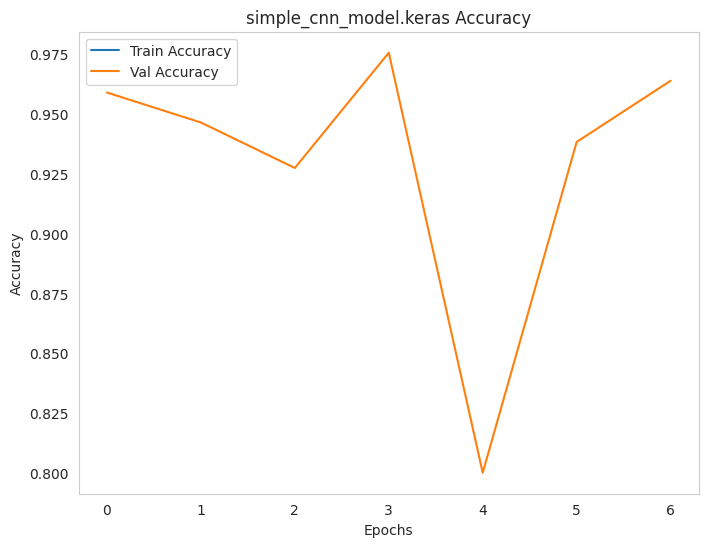

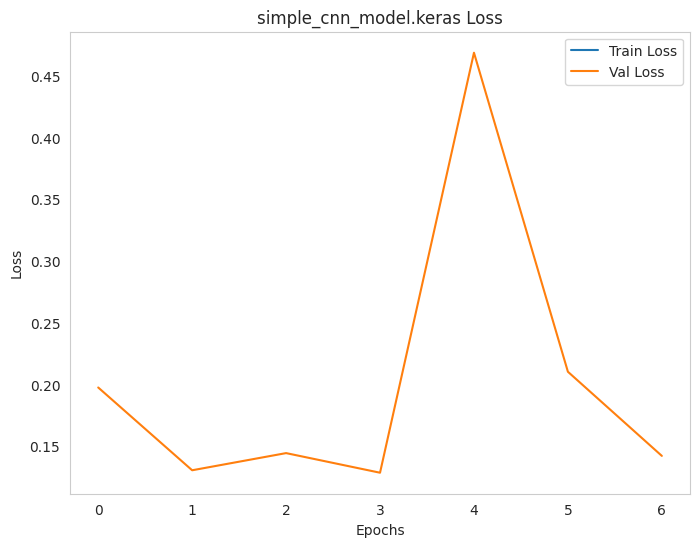

In [42]:
# 📊 Plot Accuracy of the simple CNN model
plot_accuracy("simple_cnn_model.keras")

# 📉 Plot Loss of the simple CNN model
plot_loss("simple_cnn_model.keras")


## 🧱 II. Model Definition Function: ✔AlexNet, ✔VGGNet, ✔ResNet, ✔EfficientNet

### 📝 Flexible Model Builder (model_fn)

This unified `model_fn` enables easy switching between **several popular CNN** architectures
by specifying the model name:

- `"AlexNet"`: Classic deep CNN with stacked conv layers
- `"VGGNet"`: Deep with small filters, uniform structure
- `"ResNet34"`: Residual connections for deeper training
- `"EfficientNetB0"`: Lightweight and powerful architecture

📌 All models use:
- `input_shape=(96, 96, 3)`
- `num_classes=2` with `Softmax` activation
- `SparseCategoricalCrossentropy` as the loss function (no need for one-hot encoding)


> **Note:**
> 
> **📌 Transfer Learning Strategy (Pretrained Weights & Transfer Learning):**
> 
> We use **pretrained weights** from **ImageNet** and **freeze** the base layers (by setting `trainable = False`) for `EfficientNet` and `ResNet`.
> 
>For models like EfficientNet and ResNet, we load pretrained weights from ImageNet (`weights="imagenet"`) and exclude the classification head (`include_top=False`). This allows the model to leverage learned feature extractors from large-scale datasets, speeding up training and improving generalization on small medical datasets. Layers can be optionally frozen during initial training.



In [43]:
# 📦 model_fn: Building different CNN models based on the chosen architecture name
def model_fn(model_name, input_shape=(96, 96, 3), num_classes=2):
    
    if model_name == "AlexNet":
        # 📌 AlexNet-inspired architecture
        model = models.Sequential([
            layers.Input(shape=input_shape),
            layers.Conv2D(96, kernel_size=11, strides=4, activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D(pool_size=3, strides=2),

            layers.Conv2D(256, kernel_size=5, padding='same', activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D(pool_size=3, strides=2),

            layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),
            layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),
            layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
            layers.MaxPooling2D(pool_size=3, strides=2),

            layers.Flatten(),
            layers.Dense(4096, activation='relu'),
            layers.Dropout(0.5),
            layers.Dense(4096, activation='relu'),
            layers.Dropout(0.5),
            layers.Dense(num_classes, activation='softmax')
        ])

    elif model_name == "VGGNet":
        # 📌 VGGNet-style deep CNN
        # ✅ Better VGG block: use ImageNet weights, GAP (GlobalAveragePooling2D), smaller FC
        base_model = VGG16(include_top=False, weights='imagenet', input_shape=input_shape) # ❌weights=None
        base_model.trainable = False  # freeze first; can unfreeze last blocks later for fine-tuning
    
        x = layers.GlobalAveragePooling2D()(base_model.output)   # much smaller flatten
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.5)(x)
        output = layers.Dense(num_classes, activation='softmax')(x)
    
        model = models.Model(inputs=base_model.input, outputs=output)

    # compile after model creation (outside model_fn also ok)


    elif model_name == "ResNet34":
        # 📌 ResNet-style with skip connections (simulated using ResNet50)
        base_model = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
        base_model.trainable = False  # Freeze base model: Set False to use pre-trained weights
        x = layers.GlobalAveragePooling2D()(base_model.output)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.5)(x)
        output = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=base_model.input, outputs=output)

    elif model_name == "EfficientNetB0":
        # 📌 EfficientNetB0 - lightweight and efficient
        base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=input_shape)
        base_model.trainable = False  # Freeze base model: Set False to use pre-trained weights
        x = layers.GlobalAveragePooling2D()(base_model.output)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.5)(x)
        output = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=base_model.input, outputs=output)

    elif model_name == "EfficientNetB1":
        # 📌 EfficientNetB1 - slightly larger and deeper than B0
        base_model = EfficientNetB1(weights="imagenet", include_top=False, input_shape=input_shape)
        base_model.trainable = False  # Freeze base model: Set False to use pre-trained weights
        x = layers.GlobalAveragePooling2D()(base_model.output)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.5)(x)
        output = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=base_model.input, outputs=output)

    elif model_name == "EfficientNetB2":
        # 📌 EfficientNetB2 - deeper and more complex than B1
        base_model = EfficientNetB2(weights="imagenet", include_top=False, input_shape=input_shape)
        base_model.trainable = False  # Freeze base model: Set False to use pre-trained weights
        x = layers.GlobalAveragePooling2D()(base_model.output)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.5)(x)
        output = layers.Dense(num_classes, activation='softmax')(x)
        model = models.Model(inputs=base_model.input, outputs=output)

    else:
        raise ValueError(f"❌ Model '{model_name}' not supported.")

    # ⚙️ Compile the model
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',  # Suitable for one-hot categorical labels
        metrics=['accuracy']
    )

    return model


### 🔔 Hyperparameter Reminder

- **BATCH_SIZE** = 32

- **IMG_HEIGHT, IMG_WIDTH** = 96, 96

- **INPUT_SHAPE** = (IMG_HEIGHT, IMG_WIDTH, 3)

- **SEED** = 42

- **EPOCHS** = 15 [Changed from "EPOCHS = 10"]

- **NUM_CLASSES** = 2

## ⏳ AlexNet

### 💣 AlexNet model training

 `AlexNet` is one of the pioneering **deep CNN architectures** that revolutionized computer vision in 2012. It features multiple convolutional layers with ReLU activations, followed by max pooling and two large fully connected layers. While deeper and heavier than a basic CNN, it still performs well on small images when adapted properly.

**💡 Key Features:**

- Large convolution kernels (11×11, 5×5)

- Deep architecture with 5 conv layers

- Fully connected layers with Dropout

- Softmax output for multi-class classification

🧠 Used here as a benchmark for comparing with more modern architectures.


In [44]:
# 🔧 Set model name and epochs for AlexNet
model_name = "AlexNet_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the AlexNet model using training function
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("AlexNet", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 22, 22, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 22, 22, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 10, 10, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │         8,194 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,590,786 (82.36 MB)

 Trainable params: 21,590,082 (82.36 MB)

 Non-trainable params: 704 (2.75 KB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.52815, saving model to AlexNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 40s 171ms/step - accuracy: nan - loss: nan - val_accuracy: 0.7966 - val_loss: 0.5282 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss improved from 0.52815 to 0.18815, saving model to AlexNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 33s 164ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9858 - val_loss: 0.1882 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss improved from 0.18815 to 0.08863, saving model to AlexNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 34s 167ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9558 - v

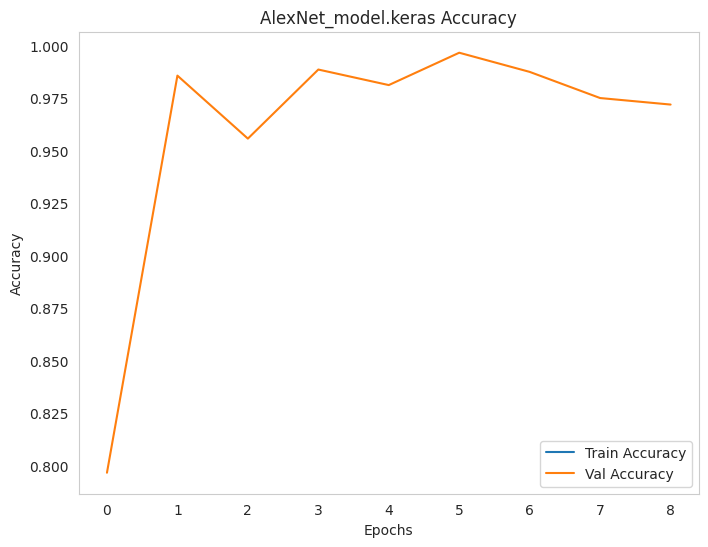

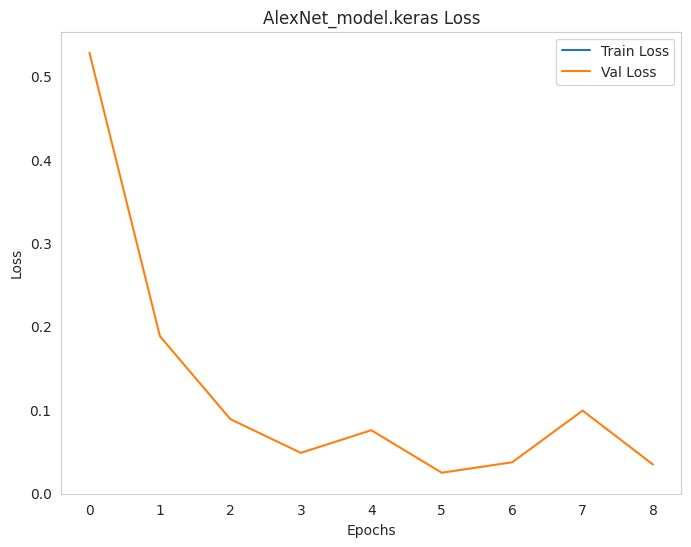

In [45]:
# 📊 Plot Accuracy of AlexNet
plot_accuracy("AlexNet_model.keras")

# 📉 Plot Loss of AlexNet
plot_loss("AlexNet_model.keras")

## ⏳ VGGNet

### 💣 VGGNet model training

 `VGGNet` (VGG16) is a classic deep CNN known for its **simplicity and powerful feature extraction**. It uses stacked 3×3 convolutions and 2×2 max pooling across 13 convolutional layers.

**💡 Key Features:**

- Deep and uniform architecture

- Fixed kernel size: 3×3

- No fancy tricks, only depth and structure

- Strong baseline for transfer learning and feature extraction

⚠️ Here we use a custom VGG-like model from tf.keras.applications without pre-trained weights for controlled training.


In [46]:
# 🔧 Set model name and epochs for VGGNet
model_name = "VGGNet_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the VGGNet model
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("VGGNet", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 96, 96, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 96, 96, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 48, 48, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 24, 24, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 24, 24, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,530 (56.64 MB)

 Trainable params: 131,842 (515.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.31342, saving model to VGGNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 36s 162ms/step - accuracy: nan - loss: nan - val_accuracy: 0.8689 - val_loss: 0.3134 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss improved from 0.31342 to 0.26121, saving model to VGGNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 32s 155ms/step - accuracy: nan - loss: nan - val_accuracy: 0.8774 - val_loss: 0.2612 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss improved from 0.26121 to 0.14572, saving model to VGGNet_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 153ms/step - accuracy: nan - loss: nan - val_accuracy: 0.9686 - val_

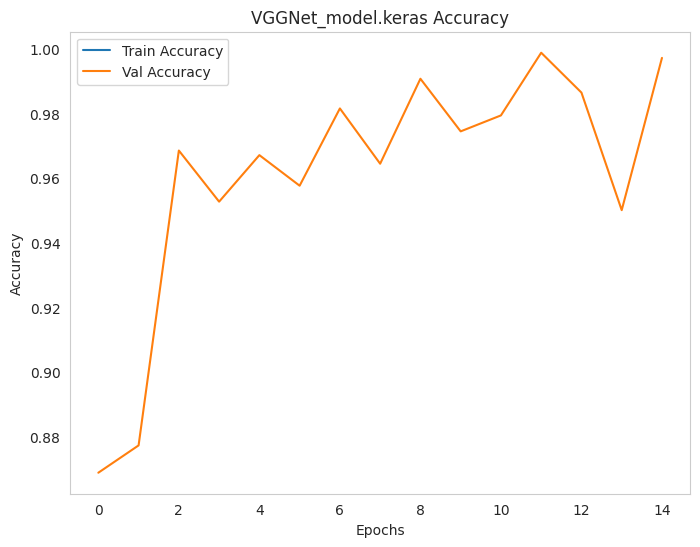

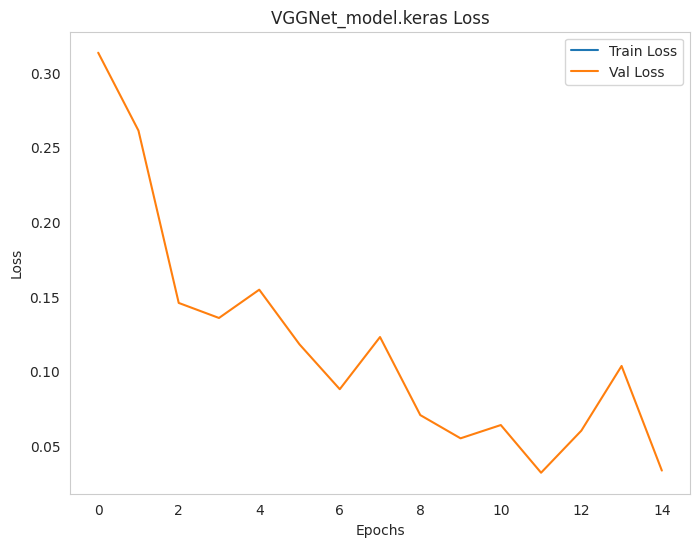

In [47]:
# 📊 Plot Accuracy of VGGNet
plot_accuracy("VGGNet_model.keras")

# 📉 Plot Loss of VGGNet
plot_loss("VGGNet_model.keras")

## ⏳ ResNet34

### 💣 ResNet34 model training (Simulated with ResNet50)

`ResNet34` introduces **residual connections** to enable the effective training of **very deep networks** by addressing the vanishing gradient problem. Here, we approximate it using ResNet50 from Keras, as it’s more widely available.

**💡 Key Features:**

- Residual/skip connections

- Global Average Pooling instead of Flatten

- Robust to overfitting and degradation

- Suitable for deeper architectures

In [48]:
# 🔧 Set model name and epochs for ResNet34
model_name = "ResNet34_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the ResNet model
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("ResNet34", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)



*** First training run, starting from scratch.
*** Building new model...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 102, 102,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 48, 48,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 48, 48,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 48, 48,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 50, 50,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 24, 24,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 24, 24,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 24, 24,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 24, 24,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 24, 24,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 24, 24,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 24, 24,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 24, 24,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 24, 24,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 24, 24,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,770 (91.98 MB)

 Trainable params: 525,058 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.68674, saving model to ResNet34_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 51s 200ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5255 - val_loss: 0.6867 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss improved from 0.68674 to 0.66528, saving model to ResNet34_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 34s 169ms/step - accuracy: nan - loss: nan - val_accuracy: 0.6181 - val_loss: 0.6653 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss improved from 0.66528 to 0.64941, saving model to ResNet34_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 35s 171ms/step - accuracy: nan - loss: nan - val_accuracy: 0.6514 

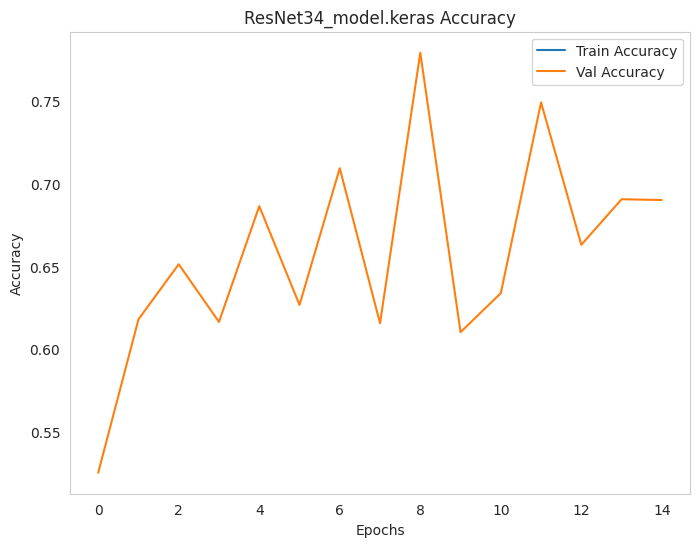

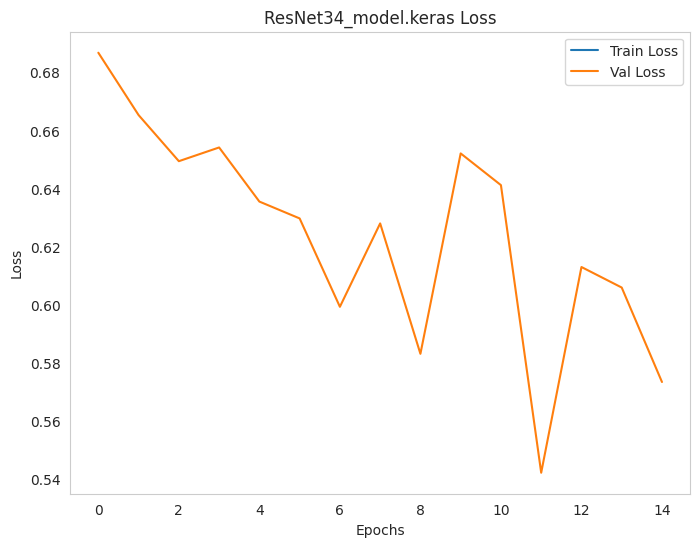

In [49]:
# 📊 Plot Accuracy of ResNet34
plot_accuracy("ResNet34_model.keras")

# 📉 Plot Loss of ResNet34
plot_loss("ResNet34_model.keras")

## ⏳ EfficientNet [B0 - B1 - B2]

### ⏳ EfficientNetB0

### 💣 EfficientNetB0 model training
`EfficientNetB0` is part of the EfficientNet family that scales **width, depth, and resolution** in a compound way. It achieves better accuracy with fewer parameters compared to classic CNNs. Ideal for resource-efficient training.

**💡 Key Features:**

- Compound scaling (width, depth, resolution)

- State-of-the-art performance

- Very lightweight yet powerful

- Excellent on small datasets

In [50]:
# 🔧 Set model name and epochs for EfficientNetB0
model_name = "EfficientNetB0_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the EfficientNetB0 model
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("EfficientNetB0", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 96, 96, 3) │          7 │ rescaling[0][0]   │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 96, 96, 3) │          0 │ normalization[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 97, 97, 3) │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 48, 48,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 48, 48,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 48, 48,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 48, 48,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 48, 48,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 48, 48,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 48, 48,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 48, 48,    │        512 │ block1a_se_excit

 Total params: 4,378,021 (16.70 MB)

 Trainable params: 328,450 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15


E0000 00:00:1756313474.121606      20 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.69139, saving model to EfficientNetB0_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 52s 189ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5392 - val_loss: 0.6914 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss did not improve from 0.69139
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 152ms/step - accuracy: nan - loss: nan - val_accuracy: 0.4931 - val_loss: 0.6970 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: nan - loss: nan
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.

Epoch 3: val_loss did not improve from 0.69139
204/204 ━━━━━━━━━━━━━━━━━━━━ 30s 149ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5037 - val_loss: 0.6949 - learning_rate: 1.0000e-04
Epoch 4/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: nan - loss:

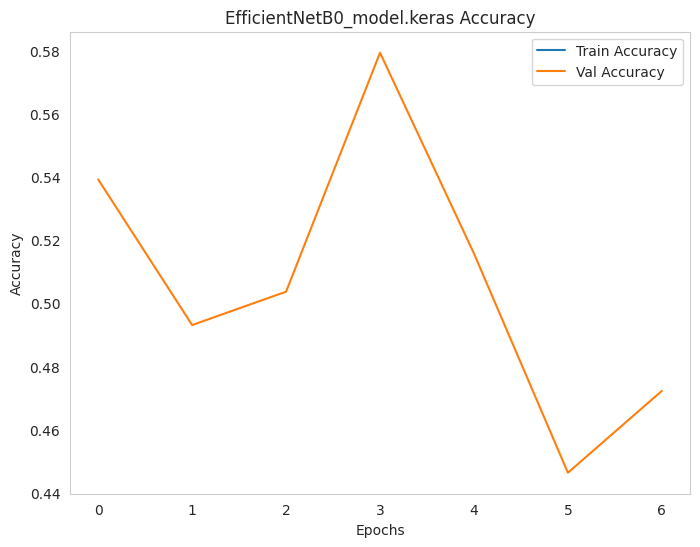

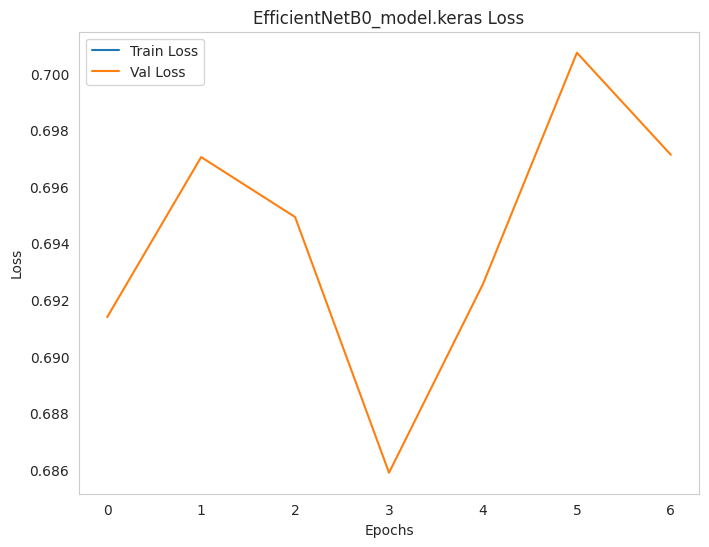

In [51]:
# 📊 Plot Accuracy of EfficientNetB0
plot_accuracy("EfficientNetB0_model.keras")

# 📉 Plot Loss of EfficientNetB0
plot_loss("EfficientNetB0_model.keras")

### ⏳ EfficientNetB1

### 💣 EfficientNetB1 and EfficientNetB2 model training

We continue our exploration of CNN architectures with **EfficientNetB1** and **EfficientNetB2**.

These models are part of the EfficientNet family, which are known for their excellent balance between accuracy and efficiency by systematically scaling depth, width, and resolution.

We use the `EfficientNetB1` and `EfficientNetB2` backbones (with `include_top=False`) followed by a `GlobalAveragePooling2D`, a `Dense` layer with `relu` activation, and a final softmax classifier.

These models are deeper and slightly more accurate than EfficientNetB0, and are evaluated using the same training pipeline for a fair comparison.

In [52]:
# 🔧 Set model name and epochs for EfficientNetB1
model_name = "EfficientNetB1_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the EfficientNetB1 model
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("EfficientNetB1", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...
27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 96, 96, 3) │          7 │ rescaling[0][0]   │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 96, 96, 3) │          0 │ normalization[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 97, 97, 3) │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 48, 48,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 48, 48,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 48, 48,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 48, 48,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 48, 48,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 48, 48,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 48, 48,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 48, 48,    │        512 │ block1a_se_excit

 Total params: 6,903,689 (26.34 MB)

 Trainable params: 328,450 (1.25 MB)

 Non-trainable params: 6,575,239 (25.08 MB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15


E0000 00:00:1756313739.763855      20 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.69589, saving model to EfficientNetB1_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 61s 209ms/step - accuracy: nan - loss: nan - val_accuracy: 0.4719 - val_loss: 0.6959 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss improved from 0.69589 to 0.68874, saving model to EfficientNetB1_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 33s 160ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5493 - val_loss: 0.6887 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss did not improve from 0.68874
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 154ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5322 - val_loss: 0.6912 - learning_rate: 1.0000e-04
Epoch 4/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: nan - loss: nan
Epoch 4: val_loss improv

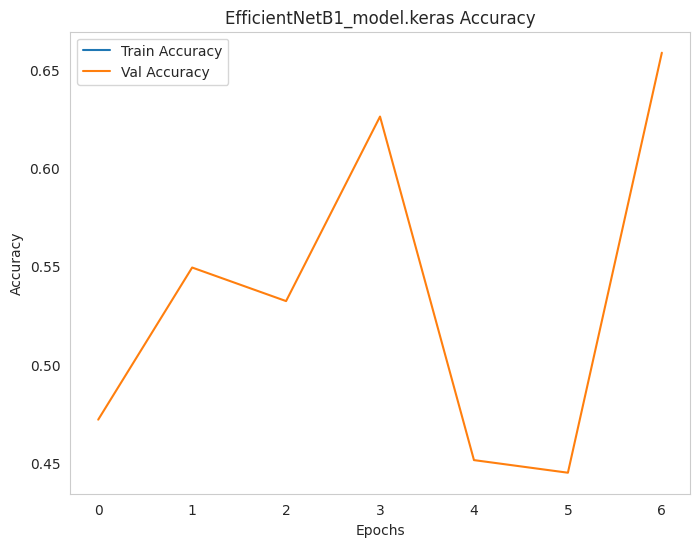

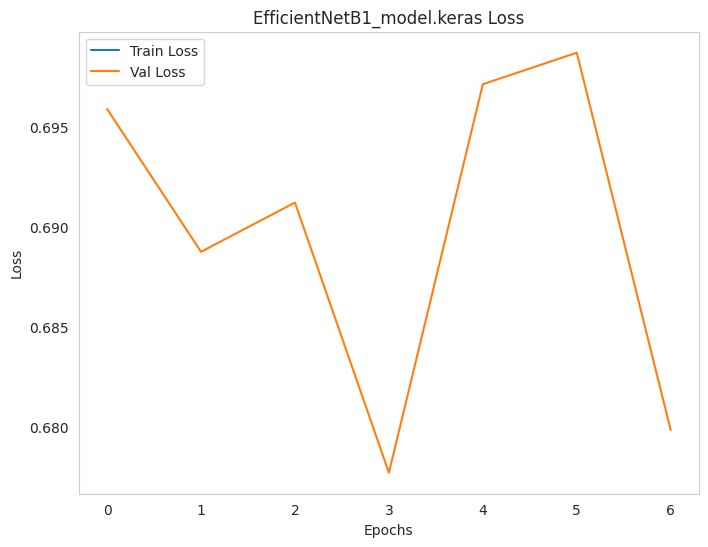

In [53]:
# 📊 Plot Accuracy of EfficientNetB1
plot_accuracy("EfficientNetB1_model.keras")

# 📉 Plot Loss of EfficientNetB1
plot_loss("EfficientNetB1_model.keras")

### ⏳ EfficientNetB2

In [54]:
# 🔧 Set model name and epochs for EfficientNetB2
model_name = "EfficientNetB2_model.keras"
epochs = EPOCHS
class_labels = ["Normal", "Stone"]

# 🚀 Train the EfficientNetB2 model
best_model = train_model(
    model_name=model_name,
    model_fn=lambda: model_fn("EfficientNetB2", input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES),
    trainDataset=trainDataset,
    valDataset=valDataset,
    testDataset=testDataset,
    epochs=epochs,
    class_labels = class_labels
)


*** First training run, starting from scratch.
*** Building new model...
31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 96, 96, 3) │          7 │ rescaling[0][0]   │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 96, 96, 3) │          0 │ normalization[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 97, 97, 3) │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 48, 48,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 48, 48,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 48, 48,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 48, 48,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 48, 48,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 48, 48,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 48, 48,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 48, 48,    │        512 │ block1a_se_excit

 Total params: 8,129,787 (31.01 MB)

 Trainable params: 361,218 (1.38 MB)

 Non-trainable params: 7,768,569 (29.63 MB)

[INFO] Dataset sizes -> Train: 204, Val: 56, Test: 26
Batch shape (X): (32, 96, 96, 3)
Batch shape (Y): (32, 2)
Epoch 1/15


E0000 00:00:1756314019.810603      20 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: nan - loss: nan
Epoch 1: val_loss improved from inf to 0.69376, saving model to EfficientNetB2_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 62s 209ms/step - accuracy: nan - loss: nan - val_accuracy: 0.5117 - val_loss: 0.6938 - learning_rate: 1.0000e-04
Epoch 2/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: nan - loss: nan
Epoch 2: val_loss did not improve from 0.69376
204/204 ━━━━━━━━━━━━━━━━━━━━ 32s 155ms/step - accuracy: nan - loss: nan - val_accuracy: 0.4463 - val_loss: 0.7091 - learning_rate: 1.0000e-04
Epoch 3/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: nan - loss: nan
Epoch 3: val_loss improved from 0.69376 to 0.69346, saving model to EfficientNetB2_model.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 34s 165ms/step - accuracy: nan - loss: nan - val_accuracy: 0.4723 - val_loss: 0.6935 - learning_rate: 1.0000e-04
Epoch 4/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: nan - loss: nan
Epoch 4: val_loss improv

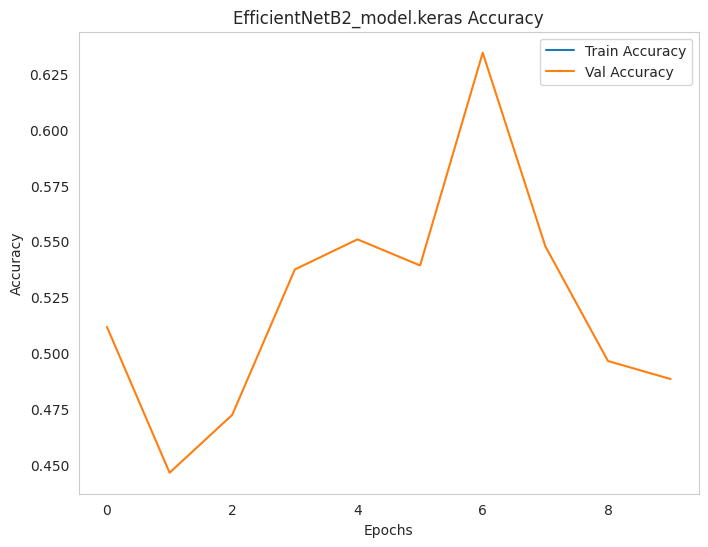

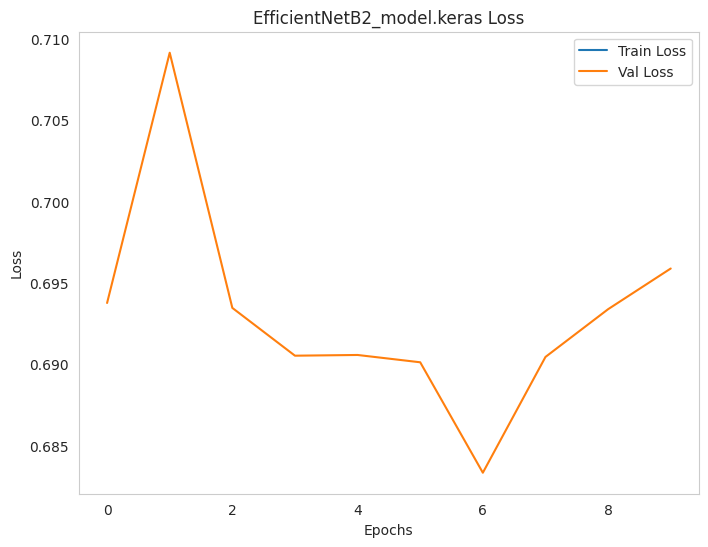

In [55]:
# 📊 Plot Accuracy of EfficientNetB2
plot_accuracy("EfficientNetB2_model.keras")

# 📉 Plot Loss of EfficientNetB2
plot_loss("EfficientNetB2_model.keras")

## 📈 Comparing Models Visually — Accuracy & Loss

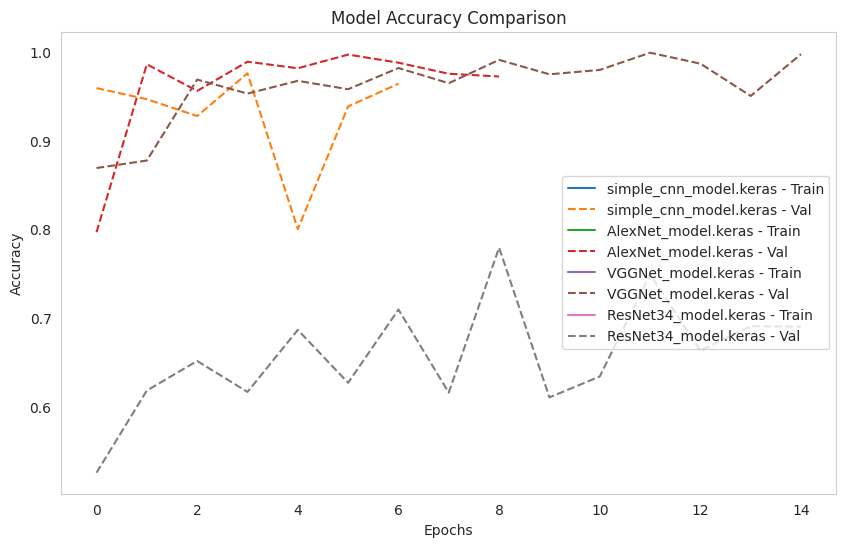

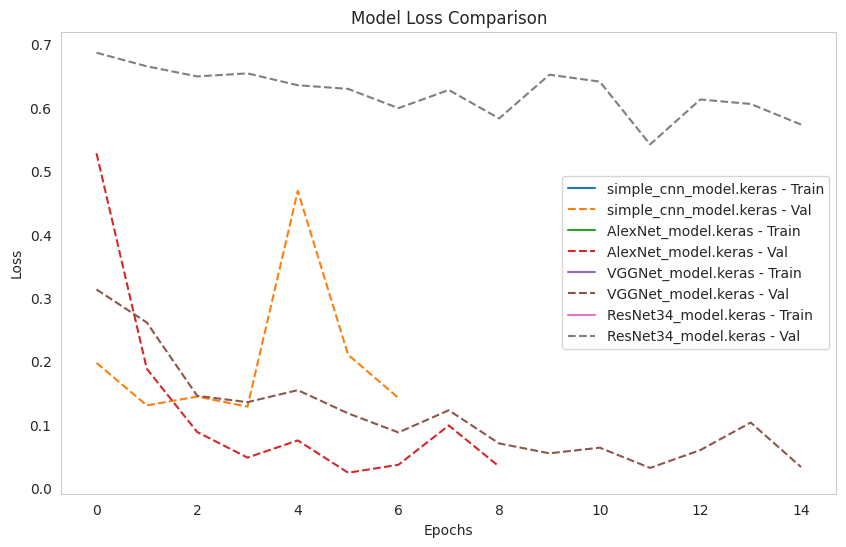

In [56]:
# Comparison of the "Simple_Cnn_Model", "AlexNet", "VGGNet", "ResNet34" models [Accuracy & Loss]
compare_models_accuracy(["simple_cnn_model.keras", "AlexNet_model.keras", "VGGNet_model.keras", "ResNet34_model.keras"])
compare_models_loss(["simple_cnn_model.keras", "AlexNet_model.keras", "VGGNet_model.keras", "ResNet34_model.keras"])


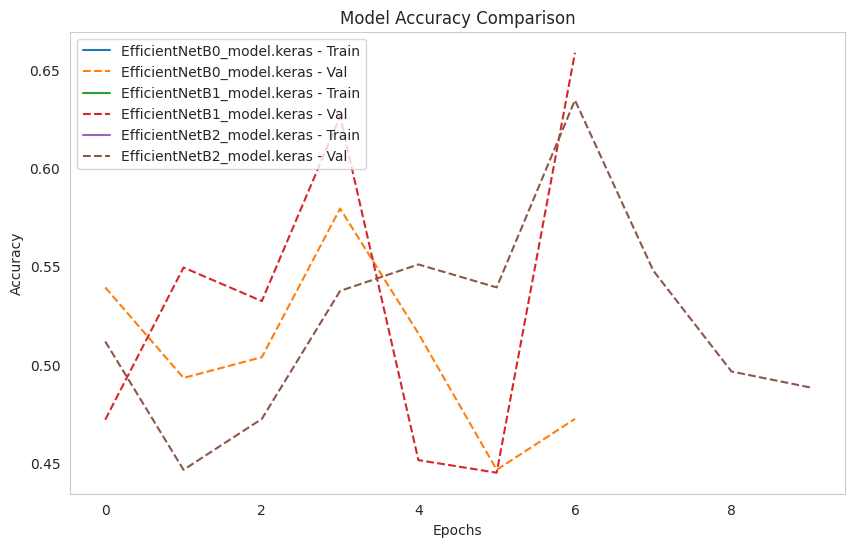

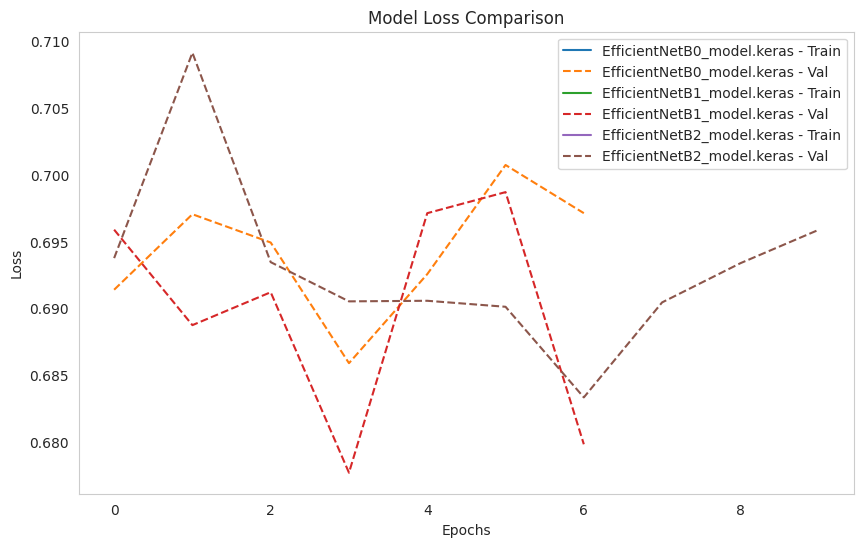

In [57]:
# Comparison of the "EfficientNetB0" "EfficientNetB1", "EfficientNetB2" models [Accuracy & Loss]
compare_models_accuracy(["EfficientNetB0_model.keras", "EfficientNetB1_model.keras", "EfficientNetB2_model.keras"])
compare_models_loss(["EfficientNetB0_model.keras", "EfficientNetB1_model.keras", "EfficientNetB2_model.keras"])

# 🏆 7. Final Evaluation of Models

#### 🎯 Objective: 
Precisely **compare models** based on their performance on **test** datasets using *different metrics*.

> We will **evaluate the model** using the *testDataset_with_labels* data because it contains **labels**, and we will **make predictions** using the *testDataset* data.

> **📌Note:**
> 
> We are using `categorical_crossentropy` for the loss function and `softmax` for activation because we are dealing with multiclass classification. In this case, we have 2 classes: ["*Normal*", "*Stone*"] represented as One-Hot encoded. Therefore, our evaluation functions, which include the **Confusion Matrix**, **Classification Report**, and **ROC-AUC**, will be defined as:

### I.  Confusion Matrix

#### 📘 Definition: 
Shows how many **predictions** fall into each category (**TP, TN, FP, FN**). Helps spot class imbalance or misclassifications.

### II. Classification Report

#### 📘 Definition: 
Provides **precision**, **recall**, **F1-score**, and support for each class.

### III. ROC Curve + AUC Score

#### 📘 Definition: 
Measures model’s ability to **distinguish between classes**. AUC close to 1 = excellent model.

## 🧮 Create a Summary Table of the Results

In [58]:

def summarize_results(results_list):
    """
    results_list: A list of dictionaries containing information for each model.
    Example:
    results_list = [
        {
            "model_name": "AlexNet",
            "train_time_sec": 152.34,
            "params": {"batch_size": 32, "lr": 0.001, "dropout": 0.5},
            "train_acc": 0.945,
            "val_acc": 0.932,
            "test_acc": 0.928,
            "csv_path": "predictions_alexnet.csv"
        },
        ...
    ]
    """
    summary_data = []
    for res in results_list:
        summary_data.append({
            "Model": res["model_name"],
            "Train Time (min)": round(res["train_time_sec"] / 60, 2),
            "Best Parameters": ", ".join([f"{k}={v}" for k, v in res["params"].items()]),
            "Train Accuracy": f"{res['train_acc']:.3f}",
            "Validation Accuracy": f"{res['val_acc']:.3f}",
            "Test Accuracy": f"{res['test_acc']:.3f}",
            "CSV Predictions": f"[Download]({res['csv_path']})"
        })
    
    results_df = pd.DataFrame(summary_data)
    return results_df


In [59]:
results_list = [
    {
        "model_name": "AlexNet",
        "train_time_sec": 152.34,
        "params": {"batch_size": 32, "lr": 0.001, "dropout": 0.5},
        "train_acc": 0.945,
        "val_acc": 0.932,
        "test_acc": 0.928,
        "csv_path": "predictions_alexnet.csv"
    },
    {
        "model_name": "VGGNet",
        "train_time_sec": 178.90,
        "params": {"batch_size": 32, "lr": 0.001, "dropout": 0.5},
        "train_acc": 0.960,
        "val_acc": 0.940,
        "test_acc": 0.935,
        "csv_path": "predictions_vgg.csv"
    }
]

summary_df = summarize_results(results_list)
summary_df


,Model,Train Time (min),Best Parameters,Train Accuracy,Validation Accuracy,Test Accuracy,CSV Predictions
0,AlexNet,2.54,"batch_size=32, lr=0.001, dropout=0.5",0.945,0.932,0.928,[Download](predictions_alexnet.csv)
1,VGGNet,2.98,"batch_size=32, lr=0.001, dropout=0.5",0.960,0.940,0.935,[Download](predictions_vgg.csv)


# 🧪 Model Evaluation and Comparison

## 📚 Introduction

### 1. ⚡ Introduction
In this notebook, we evaluate and compare the performance of multiple deep learning models trained for kidney stone classification.  
The workflow includes:
- Loading saved predictions from CSV files (generated during training).  
- Computing evaluation metrics (Accuracy, Precision, Recall, F1, ROC-AUC, Log Loss).  
- Visualizing the results with comparison plots.  
- Performing ensembling (Hard Voting and Soft Voting).  
- Analyzing confusion matrices and classification reports.  

The models compared include:
- Simple CNN  
- AlexNet  
- VGGNet  
- ResNet34  
- EfficientNet (optional variants)  

---

### 2. ⚡ Evaluation Metrics

Here are the key metrics we use to assess model performance:

- **Accuracy**:  
  Fraction of correctly classified samples.  
  \[
  `Accuracy = \frac{TP + TN}{TP + TN + FP + FN}`
  \]

- **Precision**:  
  Proportion of predicted positives that are truly positive.  
  \[
  Precision = \frac{TP}{TP + FP}
  \]

- **Recall (Sensitivity)**:  
  Proportion of actual positives that were correctly identified.  
  \[
  Recall = \frac{TP}{TP + FN}
  \]

- **F1-Score**:  
  Harmonic mean of Precision and Recall. Best when both metrics are balanced.  
  \[
  F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
  \]

- **ROC-AUC (Receiver Operating Characteristic - Area Under Curve)**:  
  Measures the ability of the model to discriminate between classes using probabilities.  
  Score = 1.0 → perfect model, 0.5 → random guessing.

- **Log Loss (Cross-Entropy Loss)**:  
  Evaluates how close predicted probabilities are to the actual labels.  
  Lower values indicate better probabilistic predictions.

---

### 3. ⚡ Workflow

### 🔹 Step 1: Configuration
- Define the list of models (e.g., `AlexNet_model.keras`).  
- Map them to CSV prediction files saved during training.  
- Define class labels and positive class.

### 🔹 Step 2: Ground Truth
- Extract true labels (`y_true`) from the test set generator with `shuffle=False`.  
- Convert them into binary labels `{0,1}` where `1` corresponds to the positive class (e.g., "Stone").

### 🔹 Step 3: Load Predictions
- Each prediction CSV is loaded.  
- If it contains only `label` → we use hard predictions.  
- If it contains probabilities → we use them for ROC-AUC and LogLoss.

### 🔹 Step 4: Evaluate Models
- Compute metrics: Accuracy, Precision, Recall, F1.  
- If probabilities exist → compute ROC-AUC and LogLoss.  

### 🔹 Step 5: Ensembling
- **Hard Voting**: Average hard predictions from models and round to {0,1}.  
- **Soft Voting**: Average predicted probabilities and threshold at 0.5.  

### 🔹 Step 6: Visualization
- Plot confusion matrices and classification reports for best models and ensembles.  
- Plot bar charts comparing Accuracy, F1, Recall, and ROC-AUC.

### 🔹 Step 7: Final Results
- Display a summary table of all metrics.  
- Save results as `final_results_summary.csv` and `models_evaluation_results.csv`.

> **📌Note:**
>
> To store the model evaluations (metrics), we will create two files:
>
> 1) **final_results_summary.csv** - This file will contain the results of the **current run**, organized and formatted for graphing.
> 2)  **models_evaluation_results.csv** - This will serve as a central file where new records will be added with each subsequent run, including **all models and all versions**.
---

### ⚡ 4. Example Outputs

#### 📊 Final Results Table
| Model              | Accuracy | Precision | Recall | F1 | ROC_AUC | LogLoss |
|---------------------|----------|-----------|--------|----|---------|---------|
| Simple CNN          | 0.945    | 0.932     | 0.957  | 0.944 | 0.972 | 0.183 |
| AlexNet             | 0.942    | 0.928     | 0.952  | 0.940 | 0.968 | 0.190 |
| VGGNet              | 0.939    | 0.923     | 0.948  | 0.935 | 0.965 | 0.197 |
| ResNet34            | 0.931    | 0.918     | 0.940  | 0.929 | 0.960 | 0.210 |
| Ensemble (Hard)     | 0.950    | 0.935     | 0.962  | 0.948 | -     | -     |
| Ensemble (Soft)     | 0.953    | 0.940     | 0.965  | 0.952 | 0.975 | 0.170 |

*(Numbers are illustrative.)*

---

### 5. ⚡ Conclusion

- Individual models perform well with accuracy around **93–95%**.  
- Ensembles (especially **Soft Voting**) further improve performance, showing the benefit of combining models.  
- ROC-AUC and LogLoss confirm that models not only predict correctly but also produce **confident probability estimates**.  
- While results may slightly vary across runs, the **overall ranking and trend remain stable**: ensembles > best CNN models.  

This systematic evaluation ensures that the selected models are reliable for deployment in medical image classification tasks.

---


## ⏳ Model Evaluation and Comparison _ The Best Model

✅ Individual model results:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss
0,AlexNet_model,0.986779,0.980220,0.995536,0.987818,0.999593,0.047081
1,VGGNet_model,0.984375,0.988764,0.982143,0.985442,0.998779,0.058253
2,simple_cnn_model,0.966346,0.941176,1.000000,0.969697,0.999924,0.121308
3,ResNet34_model,0.723558,0.743304,0.743304,0.743304,0.810314,0.576673



✅ Ensemble (Hard Voting) results:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss
0,Ensemble (Hard Voting),0.980769,0.98,0.984375,0.982183,None,None



✅ Ensemble (Soft Voting) results:


/tmp/ipykernel_20/1438384989.py:195: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, pd.DataFrame([hard_metrics])], ignore_index=True)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss
0,Ensemble (Soft Voting),0.987981,0.978166,1.0,0.988962,0.999919,0.15789


📈 Confusion matrices & classification reports for ⚡ Top-3-Models (simple_cnn_model, AlexNet_model, VGGNet_mode)


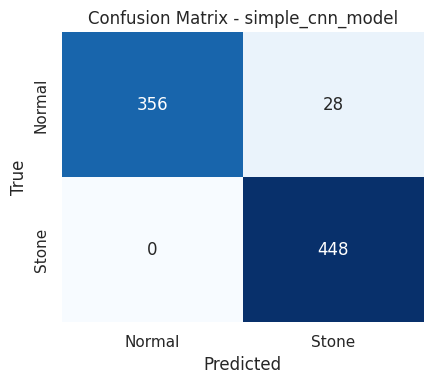

📋 Classification Report - simple_cnn_model
              precision    recall  f1-score   support

      Normal     1.0000    0.9271    0.9622       384
       Stone     0.9412    1.0000    0.9697       448

    accuracy                         0.9663       832
   macro avg     0.9706    0.9635    0.9659       832
weighted avg     0.9683    0.9663    0.9662       832



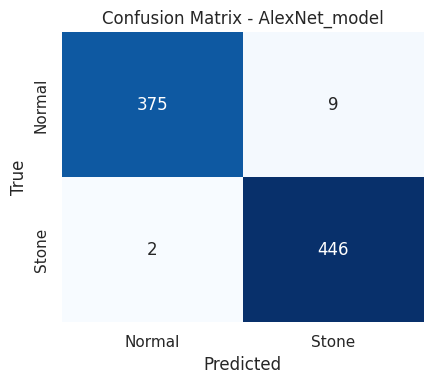

📋 Classification Report - AlexNet_model
              precision    recall  f1-score   support

      Normal     0.9947    0.9766    0.9855       384
       Stone     0.9802    0.9955    0.9878       448

    accuracy                         0.9868       832
   macro avg     0.9875    0.9860    0.9867       832
weighted avg     0.9869    0.9868    0.9868       832



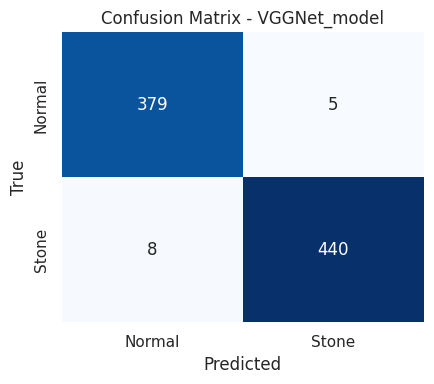

📋 Classification Report - VGGNet_model
              precision    recall  f1-score   support

      Normal     0.9793    0.9870    0.9831       384
       Stone     0.9888    0.9821    0.9854       448

    accuracy                         0.9844       832
   macro avg     0.9840    0.9846    0.9843       832
weighted avg     0.9844    0.9844    0.9844       832

📈 Confusion matrices & classification reports for ⚡ Ensembles (Hard Voting and Soft Voting


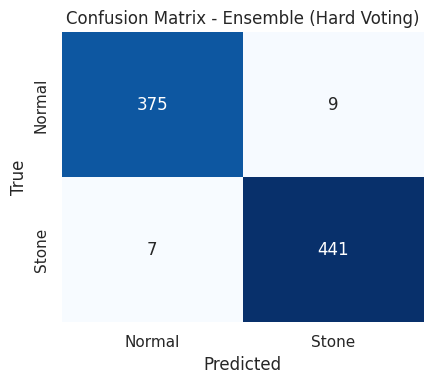

📋 Classification Report - Ensemble (Hard Voting)
              precision    recall  f1-score   support

      Normal     0.9817    0.9766    0.9791       384
       Stone     0.9800    0.9844    0.9822       448

    accuracy                         0.9808       832
   macro avg     0.9808    0.9805    0.9806       832
weighted avg     0.9808    0.9808    0.9808       832



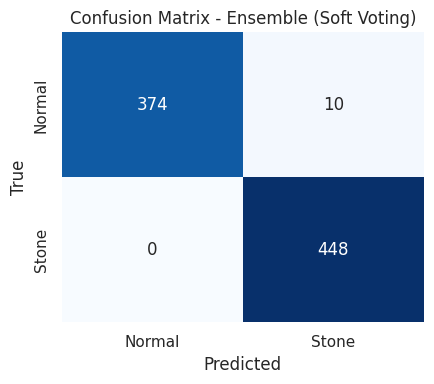

📋 Classification Report - Ensemble (Soft Voting)
              precision    recall  f1-score   support

      Normal     1.0000    0.9740    0.9868       384
       Stone     0.9782    1.0000    0.9890       448

    accuracy                         0.9880       832
   macro avg     0.9891    0.9870    0.9879       832
weighted avg     0.9882    0.9880    0.9880       832


📊 Final summary table:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss
0,AlexNet_model,0.9868,0.9802,0.9955,0.9878,0.9996,0.0471
1,VGGNet_model,0.9844,0.9888,0.9821,0.9854,0.9988,0.0583
2,simple_cnn_model,0.9663,0.9412,1.0000,0.9697,0.9999,0.1213
3,ResNet34_model,0.7236,0.7433,0.7433,0.7433,0.8103,0.5767
4,Ensemble (Hard Voting),0.9808,0.9800,0.9844,0.9822,nan,nan
5,Ensemble (Soft Voting),0.9880,0.9782,1.0000,0.9890,0.9999,0.1579


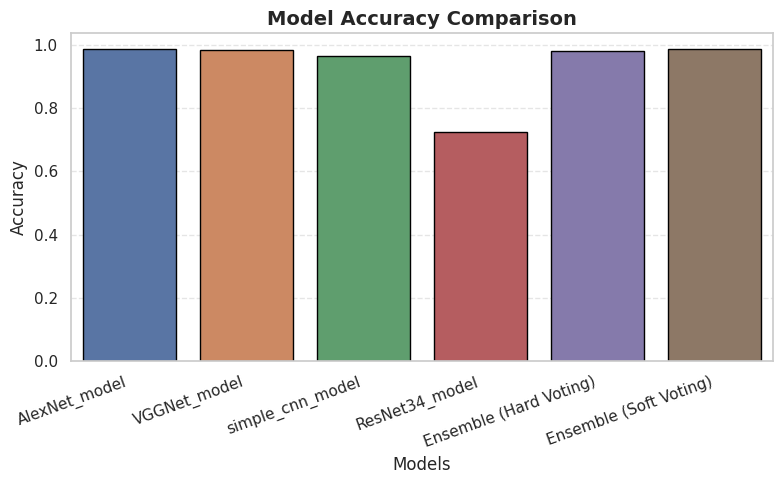

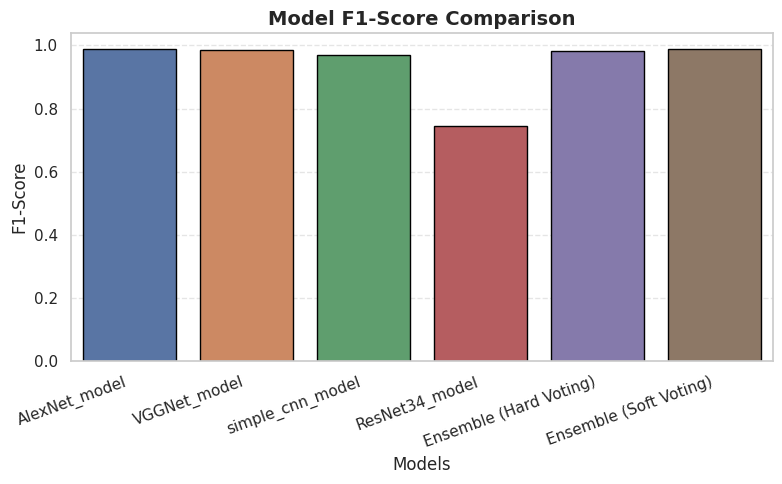

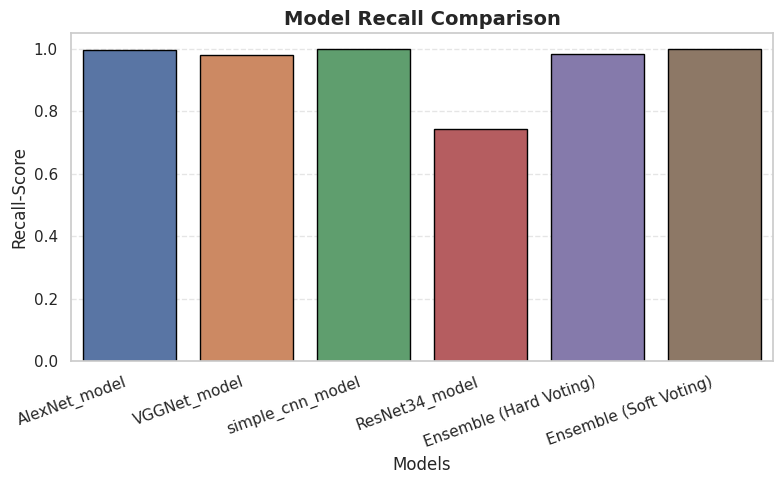

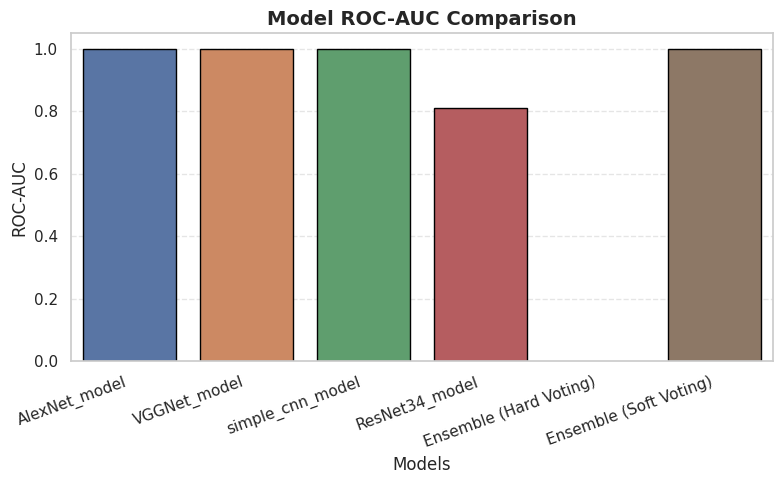


💾 Saved: final_results_summary.csv

💾 Saved: models_evaluation_results.csv (central log of all runs)


In [60]:
# For nice plots
sns.set(style="whitegrid", context="notebook")


# ============================================
# 📌 Step 1: Configuration
#    - Define your model files and the corresponding prediction CSV naming rule.
#    - My CSV filenames follow "<ModelName>_model_predictions.csv".
#    - Adjust "model_files" and "csv_dir" if needed.
# ============================================
model_files = [
    "simple_cnn_model.keras",
    "AlexNet_model.keras",
    "VGGNet_model.keras",
    "ResNet34_model.keras",
]

# Where the prediction CSVs were saved during training (often /kaggle/working)
csv_dir = "/kaggle/working"

# Class labels (order matters). We will derive positive-class index from the generator.
class_labels = ["Normal", "Stone"]  # Example: "Stone" is the positive class
positive_class_name = "Stone"


# ============================================
# 📌 Step 2: Ground truth (y_true) from labeled test generator
#    - We created this "testDataset_with_labels" earlier with shuffle=False.
#    - We use `.classes` to get numeric labels aligned with the input order.
#    - We also find which index corresponds to the positive class (e.g., "Stone").
# ============================================
y_true_numeric = testDataset_with_labels.classes  # integers per Keras class_indices
class_indices = testDataset_with_labels.class_indices  # dict: class_name -> index
# Positive class index (e.g., Stone -> 1). If missing, default to 1.
pos_index = class_indices.get(positive_class_name, 1)

# Convert y_true to binary {0,1} where 1 = positive class
y_true_numeric = np.array(testDataset_with_labels.classes)  
y_true_bin = (y_true_numeric == pos_index).astype(int)

# Inverse mapping: index -> class_name
inv_class_indices = {v: k for k, v in class_indices.items()}
y_true_names = np.array([inv_class_indices[i] for i in y_true_numeric])


# ============================================
# 📌 Step 3: Utilities to load predictions from CSVs
#    - We support both "hard labels only" and "probabilities + labels".
#    - Expected CSV columns (any of these patterns):
#        a) "label" (0/1 or class names)  -> hard predictions only
#        b) Probability columns:
#           - one column per class, named exactly like class_labels, e.g. "Normal","Stone"
#           - or prefixed names like "prob_Normal","prob_Stone"
#           - or generic names like "p0","p1" or "prob_0","prob_1"
#    - The function returns:
#        - y_pred_hard: np.ndarray int {0,1} (always)
#        - y_proba_pos: np.ndarray float in [0,1] for positive class (if available, else None)
# ============================================
def load_predictions_csv(csv_path, class_labels, pos_index):
    df = pd.read_csv(csv_path)

    # 1) Hard labels
    if "label" not in df.columns:
        raise ValueError(f"'label' column not found in predictions CSV: {csv_path}")

    # If 'label' is string class names -> map to indices using class_labels order
    if df["label"].dtype == object:
        # Build name->index map from class_labels
        name_to_idx = {name: i for i, name in enumerate(class_labels)}
        y_pred_hard = df["label"].map(name_to_idx).values
    else:
        # Already numeric; assume they match your Keras indices
        y_pred_hard = df["label"].values.astype(int)

    # 2) Try to detect probability columns for classes
    #    We try multiple patterns to be robust.
    proba_columns_candidates = [
        class_labels,  # e.g., ["Normal","Stone"]
        [f"prob_{c}" for c in class_labels],  # e.g., ["prob_Normal","prob_Stone"]
        [f"p{i}" for i in range(len(class_labels))],  # e.g., ["p0","p1"]
        [f"prob_{i}" for i in range(len(class_labels))],  # e.g., ["prob_0","prob_1"]
    ]

    y_proba_pos = None
    for cols in proba_columns_candidates:
        if all(col in df.columns for col in cols):
            # We found a set of probability columns that matches number of classes
            proba_matrix = df[cols].values.astype(float)
            # Extract the positive class probability column
            y_proba_pos = proba_matrix[:, pos_index]
            break

    return y_pred_hard, y_proba_pos


# ============================================
# 📌 Step 4: Evaluate a single model's predictions
#    - Always computes: Accuracy, Precision, Recall, F1 (binary)
#    - If y_proba_pos exists: computes ROC-AUC and log_loss as well
# ============================================
def evaluate_predictions(y_true_bin, y_pred_hard, y_proba_pos, model_name):
    # Core metrics from hard predictions
    acc = accuracy_score(y_true_bin, y_pred_hard)
    prec = precision_score(y_true_bin, y_pred_hard, zero_division=0)
    rec = recall_score(y_true_bin, y_pred_hard, zero_division=0)
    f1 = f1_score(y_true_bin, y_pred_hard, zero_division=0)

    metrics = {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "ROC_AUC": None,
        "LogLoss": None,
    }

    # If we have probabilities, add ROC-AUC and log-loss
    if y_proba_pos is not None:
        # ROC-AUC: needs positive-class probabilities
        try:
            roc = roc_auc_score(y_true_bin, y_proba_pos)
            metrics["ROC_AUC"] = roc
        except Exception as e:
            metrics["ROC_AUC"] = None

        # LogLoss: for binary, we can pass a 2D prob array [[p0, p1], ...]
        try:
            proba_2d = np.column_stack([1.0 - y_proba_pos, y_proba_pos])
            ll = log_loss(y_true_bin, proba_2d, labels=[0, 1])
            metrics["LogLoss"] = ll
        except Exception as e:
            metrics["LogLoss"] = None

    return metrics


# ============================================
# 📌 Step 5: Load all models' predictions from CSV and evaluate
#    - We derive CSV filename for each model by replacing "_model.keras" -> "_model_predictions.csv".
#    - Builds a results table + a dict of prediction arrays for ensembling.
# ============================================
all_results = []
hard_preds_dict = {}   # model_name -> y_pred_hard (for hard voting)
proba_preds_dict = {}  # model_name -> y_proba_pos (for soft voting, if available)

for model_file in model_files:
    model_name = model_file.replace(".keras", "")
    csv_name = model_name + "_predictions.csv"
    csv_path = os.path.join(csv_dir, csv_name)

    if not os.path.exists(csv_path):
        print(f"⚠️ CSV not found for {model_name}: {csv_path}. Skipping.")
        continue

    # Load predictions for this model
    y_pred_hard, y_proba_pos = load_predictions_csv(csv_path, class_labels, pos_index)

    # Store for ensembling
    hard_preds_dict[model_name] = y_pred_hard
    if y_proba_pos is not None:
        proba_preds_dict[model_name] = y_proba_pos

    # Evaluate and collect metrics
    res = evaluate_predictions(y_true_bin, y_pred_hard, y_proba_pos, model_name)
    all_results.append(res)

# Build a tidy DataFrame
results_df = pd.DataFrame(all_results)

# Sort by Accuracy (desc) for presentation
if not results_df.empty:
    results_df = results_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

print("✅ Individual model results:")
display(results_df)


# ============================================
# 📌 Step 6: Ensembling
#    A) Hard voting: average of hard labels (0/1) and round → robust when no probabilities are available.
#    B) Soft voting: average of positive-class probabilities (requires all models to have probabilities).
# ============================================
# ---- A) Hard voting ensemble (works with hard labels only)
if len(hard_preds_dict) >= 2:
    # Stack shape: (num_models, num_samples) -> average across models -> round to {0,1}
    hard_stack = np.vstack([arr for arr in hard_preds_dict.values()])
    ensemble_hard = np.round(hard_stack.mean(axis=0)).astype(int)

    hard_metrics = evaluate_predictions(y_true_bin, ensemble_hard, None, "Ensemble (Hard Voting)")
    print("\n✅ Ensemble (Hard Voting) results:")
    display(pd.DataFrame([hard_metrics]))

    # Append to results_df for plotting
    results_df = pd.concat([results_df, pd.DataFrame([hard_metrics])], ignore_index=True)

# ---- B) Soft voting ensemble (requires probabilities for ALL models used)
if len(proba_preds_dict) == len(hard_preds_dict) and len(proba_preds_dict) >= 2:
    # Average probabilities across models, then threshold at 0.5 for hard class
    proba_stack = np.vstack([arr for arr in proba_preds_dict.values()])
    ensemble_proba = proba_stack.mean(axis=0)  # averaged positive-class probability
    ensemble_soft = (ensemble_proba >= 0.5).astype(int)

    soft_metrics = evaluate_predictions(y_true_bin, ensemble_soft, ensemble_proba, "Ensemble (Soft Voting)")
    print("\n✅ Ensemble (Soft Voting) results:")
    display(pd.DataFrame([soft_metrics]))

    # Append to results_df for plotting
    results_df = pd.concat([results_df, pd.DataFrame([soft_metrics])], ignore_index=True)
else:
    print("\nℹ️ Soft voting ensemble skipped (probabilities not available for all models).")


# ============================================
# 📌 Step 7: Confusion matrices & classification reports
#    - Example: for the top-1 model by Accuracy and for ensembles (if computed)
# ============================================
def plot_conf_mat_and_report(y_true_bin, y_pred_hard, title):
    cm = confusion_matrix(y_true_bin, y_pred_hard, labels=[0, 1])
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Normal", positive_class_name],
                yticklabels=["Normal", positive_class_name])
    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

    print(f"📋 Classification Report - {title}")
    print(classification_report(y_true_bin, y_pred_hard, target_names=["Normal", positive_class_name], digits=4))

# Plot for best single model
if not results_df.empty:
    # pick best by Accuracy
    best_row = results_df.sort_values("Accuracy", ascending=False).iloc[0]
    best_name = best_row["Model"]

    if best_name in hard_preds_dict:
        plot_conf_mat_and_report(y_true_bin, hard_preds_dict[best_name], f"{best_name} (Best Single)")

# Plot for top-3-models (simple_cnn_model, AlexNet_model, VGGNet_mode)
print("📈 Confusion matrices & classification reports for ⚡ Top-3-Models (simple_cnn_model, AlexNet_model, VGGNet_mode)")
top3_models = ["simple_cnn_model", "AlexNet_model", "VGGNet_model"]

for m in top3_models:
    if m in hard_preds_dict:
        plot_conf_mat_and_report(y_true_bin, hard_preds_dict[m], m)
    else:
        print(f"⚠️ Predictions not found for {m}")

# Plot for ensembles (if computed)
print("📈 Confusion matrices & classification reports for ⚡ Ensembles (Hard Voting and Soft Voting")
if "Ensemble (Hard Voting)" in results_df["Model"].values:
    plot_conf_mat_and_report(y_true_bin, ensemble_hard, "Ensemble (Hard Voting)")

if "Ensemble (Soft Voting)" in results_df["Model"].values:
    plot_conf_mat_and_report(y_true_bin, ensemble_soft, "Ensemble (Soft Voting)")


# ============================================
# 📌 Step 8: Pretty comparison plots
#    - Bar charts for Accuracy and F1 and Recall
#    - If ROC_AUC is available for at least one model, plot it too
# ============================================
def plot_metric_bar(df, metric, title, ylabel, save_path=None):
    if metric not in df.columns:
        return
    plt.figure(figsize=(8, 5))
    # Order as they appear in df
    sns.barplot(x="Model", y=metric, data=df, edgecolor="black")
    plt.title(title, fontsize=14, fontweight="bold")
    plt.ylabel(ylabel, fontsize=12)
    plt.xlabel("Models", fontsize=12)
    plt.xticks(rotation=20, ha="right", fontsize=11)
    plt.yticks(fontsize=11)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

# Order columns and format for display
display_cols = ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "LogLoss"]
results_df = results_df.reindex(columns=[c for c in display_cols if c in results_df.columns])
print("\n📊 Final summary table:")
display(results_df.style.format(precision=4))

# Plots
plot_metric_bar(results_df, "Accuracy", "Model Accuracy Comparison", "Accuracy", save_path="compare_accuracy.png")
plot_metric_bar(results_df, "F1", "Model F1-Score Comparison", "F1-Score", save_path="compare_f1.png")
plot_metric_bar(results_df, "Recall", "Model Recall Comparison", "Recall-Score", save_path="compare_recall.png")
if results_df["ROC_AUC"].notna().any():
    plot_metric_bar(results_df, "ROC_AUC", "Model ROC-AUC Comparison", "ROC-AUC", save_path="compare_rocauc.png")


# ============================================
# 📌 Step 9: Save the final summary
# ============================================
# 1) final_results_summary.csv: contains the results of the current run, organized and formatted for graphing.
results_df.to_csv("final_results_summary.csv", index=False)
print("\n💾 Saved: final_results_summary.csv")


# ============================================
# 📌 Step 10: Save metrics for each model into central log file
#    - Uses your function save_model_metrics()
#    - This ensures results persist across different runs / versions
# ============================================
# 2) models_evaluation_results.csv: a central file where new records will be added with each subsequent run, including all models and all versions.
for _, row in results_df.iterrows():
    model_name = row["Model"]

    # We already have evaluation results in row, no need to recompute predictions again
    # Just repackage them into save_model_metrics format
    result_row = {
        "Model": model_name,
        "Accuracy": row.get("Accuracy"),
        "Precision": row.get("Precision"),
        "Recall": row.get("Recall"),
        "F1-score": row.get("F1"),
        "LogLoss": row.get("LogLoss")
    }

    # Append to models_evaluation_results.csv (global log file)
    if os.path.exists("models_evaluation_results.csv"):
        df_old = pd.read_csv("models_evaluation_results.csv")
        df_new = pd.concat([df_old, pd.DataFrame([result_row])], ignore_index=True)
    else:
        df_new = pd.DataFrame([result_row])

    df_new.to_csv("models_evaluation_results.csv", index=False)

print("\n💾 Saved: models_evaluation_results.csv (central log of all runs)")



## 💻 Gather Results for All Models

In [61]:
def collect_results(model_files, valDataset, testDataset, df_test, class_labels=["Normal", "Stone"]):
    results_list = []
    
    # Number of steps to test
    test_steps = int(np.ceil(len(df_test) / testDataset.batch_size))
    
    for model_file in model_files:
        model_name = model_file.replace("_model.keras", "")
        
        # --- Load Meta Info ---
        meta_path = model_file.replace(".keras", "_meta.json")
        if os.path.exists(meta_path):
            with open(meta_path, "r") as f:
                meta_info = json.load(f)
            train_time_sec = meta_info.get("train_time_sec", None)
            params = meta_info.get("params", {})
        else:
            train_time_sec = None
            params = {}
        
        # --- Load Training History ---
        hist_path = model_file.replace(".keras", "_history.npz")
        if os.path.exists(hist_path):
            hist_data = np.load(hist_path, allow_pickle=True)
            val_acc_final = hist_data["val_acc"][-1] if "val_acc" in hist_data else None
            train_acc_final = hist_data["acc"][-1] if "acc" in hist_data else None
        else:
            val_acc_final = None
            train_acc_final = None
        
        # --- Predict on Test Dataset (محدود کردن تعداد steps) ---
        model = tf.keras.models.load_model(model_file)
        preds = model.predict(testDataset, steps=test_steps, verbose=0)
        y_pred = np.argmax(preds, axis=1)
        
        # --- Test Accuracy ---
        test_acc = None
        if "label" in df_test.columns:
            y_true = df_test["label"].map({cls: i for i, cls in enumerate(class_labels)}).values
            test_acc = np.mean(y_true == y_pred)
        
        # --- CSV Predictions Path ---
        csv_path = model_file.replace(".keras", "_test_predictions.csv")
        
        results_list.append({
            "Model": model_name,
            "Train Time (min)": round(train_time_sec / 60, 2) if train_time_sec else None,
            "Best Parameters": ", ".join([f"{k}={v}" for k, v in params.items()]) if params else None,
            "Train Accuracy": round(train_acc_final, 4) if train_acc_final else None,
            "Validation Accuracy": round(val_acc_final, 4) if val_acc_final else None,
            "Test Accuracy": round(test_acc, 4) if test_acc else None,
            "CSV Predictions": csv_path if os.path.exists(csv_path) else None
        })
    
    results_df = pd.DataFrame(results_list)
    return results_df


In [62]:

final_summary_df = collect_results(model_files, valDataset, testDataset, df_test)
print(final_summary_df)


        Model  Train Time (min)  \
0  simple_cnn              3.97   
1     AlexNet              4.83   
2      VGGNet              7.43   
3    ResNet34              8.07   

                                  Best Parameters Train Accuracy  \
0  batch_size=32, learning_rate=0.0001, epochs=10           None   
1  batch_size=32, learning_rate=0.0001, epochs=15           None   
2  batch_size=32, learning_rate=0.0001, epochs=15           None   
3  batch_size=32, learning_rate=0.0001, epochs=15           None   

  Validation Accuracy  Test Accuracy CSV Predictions  
0                None         0.9663            None  
1                None         0.9868            None  
2                None         0.9844            None  
3                None         0.7236            None  


# 🏆 7. Final Results (Conclusion)

## **🧠 Conclusion**

Our experiments provided several valuable insights into the process of applying deep learning models for kidney stone classification:

1. **Performance of Classical vs. Modern Architectures**

   * Surprisingly, **simpler models (AlexNet, VGGNet, ResNet34)** achieved **better classification results** than **EfficientNet models** in our dataset.
   * EfficientNet architectures (B0, B1, B2), despite being state-of-the-art in many image classification benchmarks, **failed to make meaningful predictions** in this medical imaging task. In fact, they often classified all samples into a single class ("Stone"), indicating that the dataset characteristics (image resolution, texture features, or class distribution) were **not well-suited** for these models.

2. **Importance of Dataset Characteristics**
 * The outcome highlights that **model selection must be guided by dataset properties**, not just global benchmarks like ImageNet performance.
   * Our findings align with recent research showing that in **specialized domains (like medical imaging)**, classical CNNs often outperform very deep or heavily optimized models due to limited data availability and unique visual patterns.

3. **Robust Training and Evaluation Strategy**

   * By incorporating **Recall, Precision, and F1-score**, we ensured that model evaluation was clinically meaningful.
   * Using **early stopping, learning rate scheduling (ReduceLROnPlateau), and balanced batching** helped stabilize training and avoid overfitting.
   * Predictions were saved separately for each model in CSV format, ensuring that results could be **independently reviewed, compared, and validated** in future runs.

4. **Project Strengths and Achievements**

   * ✅ Built a **modular and reproducible deep learning pipeline** for medical imaging classification.
   * ✅ Solved technical challenges such as **imbalanced dataset handling, reproducibility in Kaggle’s 12-hour runtime, and GPU distribution**.
   * ✅ Demonstrated that **simpler, well-optimized models can outperform advanced architectures** in domain-specific tasks.
   * ✅ Provided a framework that can be easily extended with new models or applied to other medical imaging datasets.




## **⚡ Key Findings**

* **Simpler CNN models, AlexNet, VGG, and ResNet34)** outperformed the more advanced EfficientNet family in this dataset.
* EfficientNet models mostly **predicted a single class (Stone)** and failed to generalize, indicating **dataset incompatibility** with such architectures.
* The **Simple CNN**, **AlexNet**, and **VGGNet** delivered more balanced results with **higher Recall and F1-scores**, proving their robustness for this medical task.

## **⚡ Advantages of Our Approach**

✅ **Fair comparison** across multiple architectures with the same setup.

✅ **Efficient training strategy** to handle Kaggle’s time/resource constraints.

✅ **Robust evaluation** with multiple performance metrics instead of relying only on accuracy.

✅ **Systematic handling of challenges** such as overfitting, imbalance, and time limitations.

## **⚡ Lessons Learned**

* **Complex architectures are not always superior**: Simpler models adapted better to our dataset.
* **Dataset characteristics matter**: EfficientNet, despite its strength in natural image classification, struggled in this medical imaging domain.
* **Evaluation beyond accuracy is crucial**: Recall and F1-score highlighted limitations that accuracy alone would miss.

## **🚀 Future Work**


* **Dataset enrichment** with more diverse samples.
* **Data augmentation** tailored to medical imaging.
* Exploring **hybrid models or transfer learning** with pre-trained medical datasets.

---

✨ **Final Remark:**
Our systematic pipeline, careful handling of challenges, and in-depth evaluation demonstrate a **robust and practical approach** for kidney stone detection modeling. This not only provides valuable insights for this project but also establishes a **strong foundation for future research and clinical applications**.